# Учебное исследование города Приморск (Выборгский район, Ленинградская область, Россия) с помощью BlocksNet 1.0.0.a9

**Цель:** подготовить данные, выделить городские кварталы, загрузить пешеходный граф дорожной сети и посчитать *все* показатели из `examples/pipeline.ipynb` для города Приморск.

**Важные ограничения:**
- Рабочая среда: Windows. Все команды ниже даны под PowerShell.
- Версия библиотеки: `blocksnet == 1.0.0a9` (установлена в окружении).
- Только пешеходный граф (`network_type='walk'`), без интермодального расчёта.
- Скачивание данных, расчёты и построение графа **выполняешь самостоятельно** при запуске ячеек ноутбука. Я ничего не скачивал и не запускал.
- Используется **только** граница города Приморск (не всё Приморское городское поселение).
- Результаты сохраняются в `GeoJSON`. Весь промежуточный результат можно переиспользовать без повторного скачивания.
- Расчёт времени в пути выполняется по **только одному** пешеходному графу, время переводится в **минуты**.

## 1. Подготовка окружения

В этом блоке - только проверка. **Ничего не устанавливаем.** Опираемся на существующий `pyproject.toml` текущего проекта.

**Проверка зависимостей из pyproject.toml:**
- В `dependencies` текущего `pyproject.toml` блок `blocksnet` отсутствует. Это нужно будет добавить в дальнейшем при подготовке окружения под публикацию/развёртывание. **Второй файл зависимостей создавать не будем**.
- Для работы по пайплайну потребуются: `blocksnet==1.0.0a9`, `geopandas`, `osmnx`, `networkx`, `shapely`, `pyproj`, `matplotlib` (для быстрой визуальной проверки).

In [1]:
# Проверка версий установленных библиотек (только чтение)
import sys
print('Python:', sys.version)

try:
    import blocksnet
    print('blocksnet:', blocksnet.__version__)
except Exception as e:
    print('blocksnet: НЕ НАЙДЕН -', e)

try:
    import geopandas as gpd
    print('geopandas:', gpd.__version__)
except Exception as e:
    print('geopandas: НЕ НАЙДЕН -', e)

try:
    import osmnx as ox
    print('osmnx:', ox.__version__)
except Exception as e:
    print('osmnx: НЕ НАЙДЕН -', e)

try:
    import networkx as nx
    print('networkx:', nx.__version__)
except Exception as e:
    print('networkx: НЕ НАЙДЕН -', e)

try:
    import shapely
    print('shapely:', shapely.__version__)
except Exception as e:
    print('shapely: НЕ НАЙДЕН -', e)

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
blocksnet: 1.0.0a9
geopandas: 1.2.0
osmnx: 2.1.1
networkx: 3.6.1
shapely: 2.2.0


### Команды для Windows (PowerShell) для работы с ноутбуком

Выполняй по мере надобности **в терминале PowerShell** из корня проекта:

```powershell
# Активировать venv, если используется
.\.venv\Scripts\Activate.ps1

# Запуск Jupyter Lab
jupyter lab

# Или Jupyter Notebook
jupyter notebook
```

**Порядок работы:** запускай ячейки по порядку. **После раздела 3** будет явная остановка - не переходи к расчёту показателей, пока не задумаешься о доступных метриках (как указано ниже).

## 2. Структура папок для данных

Создадим папку для всех исходных, промежуточных и итоговых файлов. Будем проверять наличие файлов и при повторном запуске использовать уже сохранённые.

Путь: `data/primorsk_blocksnet/`

In [2]:
from pathlib import Path

DATA_DIR = Path('data/primorsk_blocksnet')
DATA_DIR.mkdir(parents=True, exist_ok=True)
print('Папка данных:', DATA_DIR.resolve())

# Пути под сохранение
PATH_BOUNDARY = DATA_DIR / 'boundary_primorsk.geojson'
PATH_WATER = DATA_DIR / 'water.geojson'
PATH_ROADS = DATA_DIR / 'roads.geojson'
PATH_RAILWAYS = DATA_DIR / 'railways.geojson'
PATH_BLOCKS = DATA_DIR / 'blocks.geojson'
PATH_GRAPH_GraphML = DATA_DIR / 'graph.graphml'
PATH_INDICATORS = DATA_DIR / 'indicators.geojson'

print('Готовые пути настроены.')

Папка данных: D:\ИТМО\Курс ИИ технологии\python-package-boilerplate\data\primorsk_blocksnet
Готовые пути настроены.


## 3. Загрузка границ и исходных слоёв. Подготовка кварталов

Здесь мы получаем **только границу города Приморск** (Выборгский район, Ленинградская область, Россия). Важно: не Приморское городское поселение целиком, а именно город Приморск.

Будем использовать подход из `examples/pipeline.ipynb` с `osmnx.geocode_to_gdf`, фильтровать по типам геометрии, приводить к UTM CRS, предобрабатывать и нарезать кварталы через `blocksnet.blocks.cutting`.

### 3.1. Получение границы города Приморск (с визуальной проверкой)

**Пояснения простыми словами:**
- Сначала пробуем точный запрос: `"Приморск, Выборгский район, Ленинградская область, Россия"` или вариант `"город Приморск"`. 
- Далее **обязательно** делаем визуальную проверку границы на карте, чтобы убедиться, что это именно город, а не всё поселение.
- Если при проверке граница окажется слишком большой (включает окрестные территории поселения) - вместо простого geocode лучше будет использовать более точный поиск/фильтрацию. Но для начала делаем именно так, как в примере, с проверкой.

Файл границы не найден. Будет выполнен запрос через osmnx.geocode_to_gdf.
Запрос: "Приморск, Выборгский район, Ленинградская область, Россия"
Граница сохранена в: data\primorsk_blocksnet\boundary_primorsk.geojson


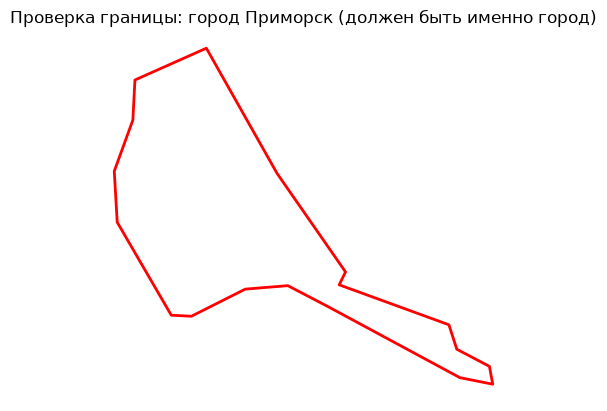

                                            geometry  bbox_west  bbox_south  \
0  POLYGON ((28.59984 60.36833, 28.59989 60.36793...  28.599844   60.340777   

   bbox_east  bbox_north   place_id osm_type     osm_id        lat        lon  \
0  28.698837   60.384238  176929961      way  100648422  60.366665  28.616673   

   class  type  place_rank  importance addresstype      name  \
0  place  town          18    0.532846        town  Primorsk   

                                        display_name  
0  Primorsk, Приморское городское поселение, Vybo...  


In [3]:
# Загрузка границы с проверкой наличия сохранённого файла
import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt

if PATH_BOUNDARY.exists():
    print('Найден сохранённый файл границы:', PATH_BOUNDARY)
    boundaries = gpd.read_file(PATH_BOUNDARY)
    print('Загружено из файла.')
else:
    print('Файл границы не найден. Будет выполнен запрос через osmnx.geocode_to_gdf.')
    print('Запрос: "Приморск, Выборгский район, Ленинградская область, Россия"')
    # ВАЖНО: запуск этой ячейки выполнит запрос к OSM. Ты запускаешь самостоятельно.
    boundaries = ox.geocode_to_gdf('Приморск, Выборгский район, Ленинградская область, Россия')
    # Сохраняем сразу для повторного использования
    boundaries.to_file(PATH_BOUNDARY, driver='GeoJSON')
    print('Граница сохранена в:', PATH_BOUNDARY)

# Визуальная проверка границы
ax = boundaries.plot(edgecolor='red', facecolor='none', linewidth=2)
ax.set_title('Проверка границы: город Приморск (должен быть именно город)')
ax.set_axis_off()
plt.show()

print(boundaries)

### 3.2. Загрузка дорог, ж/д, водных объектов по тегам (как в pipeline)

Используем теги из примера BlocksNet. Сохраняем слои в GeoJSON для повторного использования.

In [6]:
import osmnx as ox

ox.settings.overpass_url = "https://overpass.kumi.systems/api"
ox.settings.use_cache = True
ox.settings.overpass_rate_limit = True

print("Сервер Overpass настроен:", ox.settings.overpass_url)

Сервер Overpass настроен: https://overpass.kumi.systems/api


In [9]:
import osmnx as ox

ox.settings.overpass_url = "https://overpass-api.de/api"
ox.settings.requests_timeout = 120
ox.settings.use_cache = True

print("Настройки OSMnx обновлены")

Настройки OSMnx обновлены


In [ ]:
bc_tags = {
    'roads': {
      "highway": ["living_street","pedestrian","primary","residential","road","secondary","services","tertiary","unclassified"],
      "service": ["living_street", "emergency_access"]
    },
    'railways': {
      "railway": "rail"
    },
    'water': {
      'riverbank':True,
      'reservoir':True,
      'basin':True,
      'dock':True,
      'canal':True,
      'pond':True,
      'natural': ['water', 'bay', 'strait'],
      'waterway':['river','canal','ditch'],
      'landuse':'basin',
      'water': 'lake'
    }
}

# Загрузка с проверкой файлов
def load_or_fetch_features(polygon_gdf, tags, save_path, name):
    if save_path.exists():
        print(f'{name}: найден сохранённый файл {save_path}, загружаем...')
        gdf = gpd.read_file(save_path)
        return gdf
    else:
        print(f'{name}: файла нет. Будет загрузка через ox.features_from_polygon (запуском ячейки).')
        # union_all для совместимости
        try:
            poly = polygon_gdf.union_all()
        except Exception:
            poly = polygon_gdf.geometry.unary_union
        gdf = ox.features_from_polygon(poly, tags)
        gdf.to_file(save_path, driver='GeoJSON')
        print(f'{name}: сохранён в {save_path}')
        return gdf

# Получаем данные
water = load_or_fetch_features(boundaries, bc_tags['water'], PATH_WATER, 'water')
roads = load_or_fetch_features(boundaries, bc_tags['roads'], PATH_ROADS, 'roads')
railways = load_or_fetch_features(boundaries, bc_tags['railways'], PATH_RAILWAYS, 'railways')

print('Слои загружены.')

water: найден сохранённый файл data\primorsk_blocksnet\water.geojson, загружаем...
roads: найден сохранённый файл data\primorsk_blocksnet\roads.geojson, загружаем...
railways: найден сохранённый файл data\primorsk_blocksnet\railways.geojson, загружаем...
Слои загружены.


### 3.3. Фильтрация геометрий и приведение к CRS

Фильтруем по типам геометрий как в примере, переводим всё в UTM для корректной нарезки.

UTM CRS: EPSG:32635
CRS приведён.


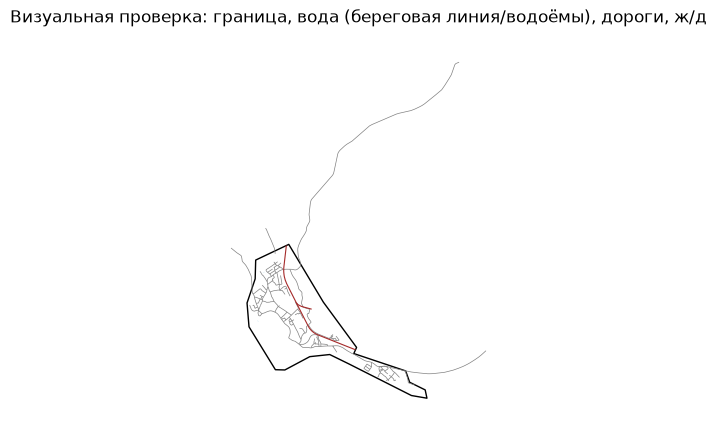

In [15]:
# Фильтрация
water_f = water[water.geom_type.isin(['Polygon', 'MultiPolygon', 'LineString', 'MultiLineString'])].copy()
roads_f = roads[roads.geom_type.isin(['LineString', 'MultiLineString'])].copy()
railways_f = railways[railways.geom_type.isin(['LineString', 'MultiLineString'])].copy()
boundaries_f = boundaries.copy()

# CRS
crs = boundaries_f.estimate_utm_crs()
print('UTM CRS:', crs)

for gdf in [water_f, roads_f, railways_f, boundaries_f]:
    gdf.to_crs(crs, inplace=True)

print('CRS приведён.')

# Визуальная проверка береговой линии и транспортной сети
ax = boundaries_f.plot(edgecolor='black', facecolor='none')
water_f.plot(ax=ax, color='lightblue', alpha=0.6)
roads_f.plot(ax=ax, color='grey', linewidth=0.5)
railways_f.plot(ax=ax, color='brown', linewidth=0.8)
ax.set_title('Визуальная проверка: граница, вода (береговая линия/водоёмы), дороги, ж/д')
ax.set_axis_off()
plt.show()

### 3.4. Предобработка и нарезка городских кварталов

Используем `preprocess_urban_objects` и `cut_urban_blocks` из `blocksnet.blocks.cutting` как в `pipeline.ipynb`.

Участков береговой линии: 3


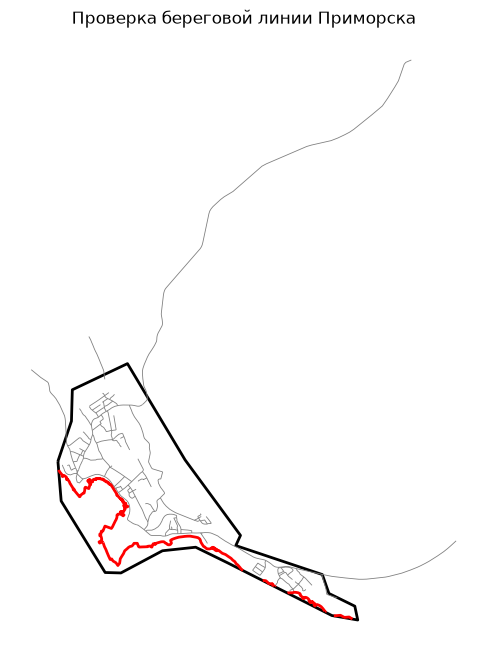

In [17]:

import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
from pathlib import Path

PATH_COAST = DATA_DIR / "coastline.geojson"

if PATH_COAST.exists():
    coastline = gpd.read_file(PATH_COAST).to_crs(crs)
    print("Береговая линия загружена из файла.")
else:
    # Ищем береговую линию с запасом 500 м
    search_area = boundaries_f.buffer(500).union_all()
    search_area = gpd.GeoSeries(
        [search_area], crs=crs
    ).to_crs(4326).iloc[0]

    coastline = ox.features_from_polygon(
        search_area,
        {"natural": "coastline"}
    )

    coastline = coastline[
        coastline.geom_type.isin(
            ["LineString", "MultiLineString"]
        )
    ].copy().to_crs(crs)

    coastline = gpd.clip(coastline, boundaries_f)
    coastline = coastline[
        coastline.geom_type.isin(
            ["LineString", "MultiLineString"]
        )
    ].copy()

    if not coastline.empty:
        coastline.to_file(PATH_COAST, driver="GeoJSON")

print("Участков береговой линии:", len(coastline))

fig, ax = plt.subplots(figsize=(10, 8))
boundaries_f.boundary.plot(
    ax=ax, color="black", linewidth=2
)
roads_f.plot(ax=ax, color="gray", linewidth=0.6)

if not coastline.empty:
    coastline.plot(ax=ax, color="red", linewidth=2)

ax.set_title("Проверка береговой линии Приморска")
ax.set_axis_off()
plt.show()
  

In [18]:
import pandas as pd

coastline_f = coastline.to_crs(crs)

water_f = gpd.GeoDataFrame(
    pd.concat(
        [
            water_f[['geometry']],
            coastline_f[['geometry']]
        ],
        ignore_index=True
    ),
    geometry='geometry',
    crs=crs
)

print("Водных объектов и участков берега:",
      len(water_f))

Водных объектов и участков берега: 7


Polygon            4
MultiLineString    2
LineString         1
Name: count, dtype: int64


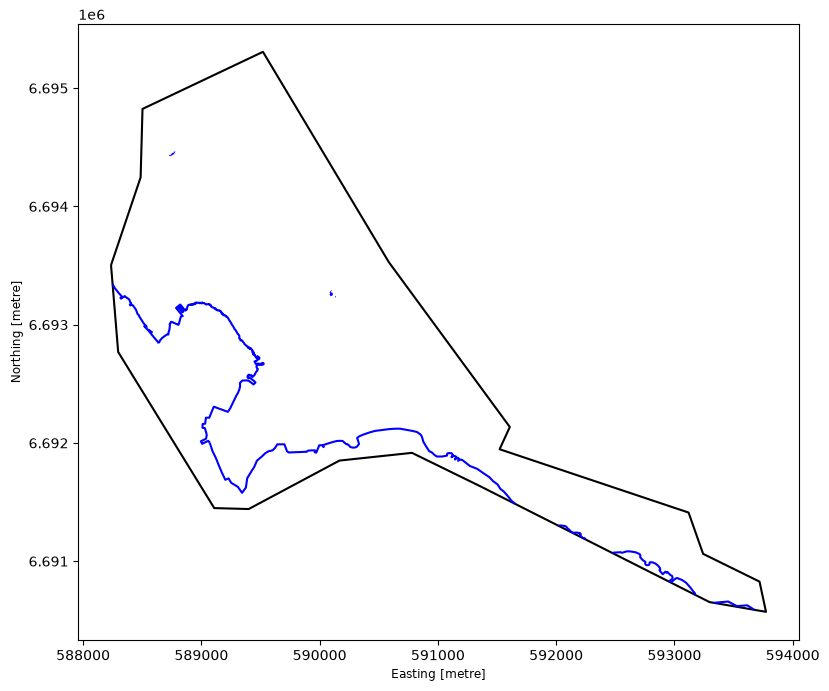

In [19]:
print(water_f.geom_type.value_counts())

ax = boundaries_f.boundary.plot(
    color='black', figsize=(10, 8)
)
water_f.plot(
    ax=ax, color='blue', linewidth=1.5
)
plt.show()

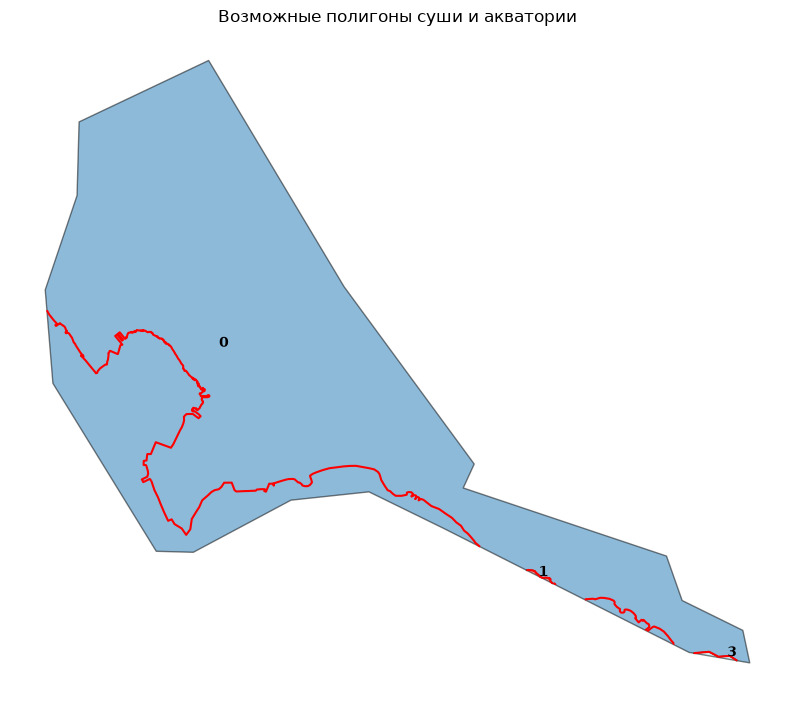

Получено полигонов: 3
   id
3   3
1   1
0   0


In [21]:

import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.ops import unary_union, polygonize

coast = coastline.to_crs(crs)

boundary_line = boundaries_f.geometry.boundary.union_all()

combined_lines = unary_union([
    boundary_line,
    coast.geometry.union_all()
])

candidate_polygons = list(polygonize(combined_lines))

candidates = gpd.GeoDataFrame(
    {"id": range(len(candidate_polygons))},
    geometry=candidate_polygons,
    crs=crs
)

candidates = gpd.clip(candidates, boundaries_f)
candidates = candidates[candidates.area > 100].copy()

fig, ax = plt.subplots(figsize=(10, 9))

candidates.plot(
    ax=ax,
    column="id",
    cmap="tab20",
    alpha=0.5,
    edgecolor="black"
)

for _, row in candidates.iterrows():
    p = row.geometry.representative_point()
    ax.text(
        p.x, p.y, str(row["id"]),
        fontsize=10, weight="bold"
    )

coast.plot(
    ax=ax, color="red", linewidth=1.5
)

ax.set_title("Возможные полигоны суши и акватории")
ax.set_axis_off()
plt.show()

print("Получено полигонов:", len(candidates))
print(candidates[["id"]])
  

In [22]:

import osmnx as ox
import geopandas as gpd

# Дополнительные теги для поиска акватории
water_extra_tags = {
    "natural": ["strait", "bay", "water"],
    "water": ["strait", "sea"],
    "place": ["sea", "locality"]
}

search_polygon = boundaries.to_crs(4326).buffer(0.02).union_all()

water_extra = ox.features_from_polygon(
    search_polygon,
    water_extra_tags
)

print("Найдено объектов:", len(water_extra))
print(water_extra.geom_type.value_counts())

columns = [
    c for c in ["name", "natural", "water", "place"]
    if c in water_extra.columns
]
print(water_extra[columns].to_string())
    

C:\Users\Honor\AppData\Local\Temp\ipykernel_33468\989013670.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  search_polygon = boundaries.to_crs(4326).buffer(0.02).union_all()


Найдено объектов: 7
Polygon       5
Point         1
LineString    1
Name: count, dtype: int64
                                   name natural
element  id                                    
node     13028643061   бухта Катерлахти     bay
relation 9890419      пролив Бьёркезунд  strait
way      93127501                   NaN   water
         93860141                   NaN   water
         93860146                   NaN   water
         137459107                  NaN   water
         171553120    пролив Бьёркезунд  strait


In [23]:
check = water_extra.copy()

check["geometry_type"] = check.geom_type
check["area_km2"] = (
    check.to_crs(32635).geometry.area / 1_000_000
).round(3)

print(
    check[
        ["name", "natural", "geometry_type", "area_km2"]
    ].to_string()
)

                                   name natural geometry_type  area_km2
element  id                                                            
node     13028643061   бухта Катерлахти     bay         Point     0.000
relation 9890419      пролив Бьёркезунд  strait       Polygon    93.943
way      93127501                   NaN   water       Polygon     0.001
         93860141                   NaN   water       Polygon     0.001
         93860146                   NaN   water       Polygon     0.000
         137459107                  NaN   water       Polygon     0.001
         171553120    пролив Бьёркезунд  strait    LineString     0.000


2026-10-23 15:13:18.886 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema
2026-10-23 15:13:18.894 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema
2026-10-23 15:13:18.902 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema
2026-10-23 15:13:18.910 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema
2026-10-23 15:13:18.916 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:55 - Checking line objects schema
2026-10-23 15:13:18.925 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:62 - Checking polygon objects schema
2026-10-23 15:13:18.933 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:69 - Checking buildings schema
2026-10-23 15:13:18.934 

Файл кварталов не найден. Выполняем предобработку и нарезку (запуском ячейки).
Кварталы сохранены в: data\primorsk_blocksnet\blocks.geojson


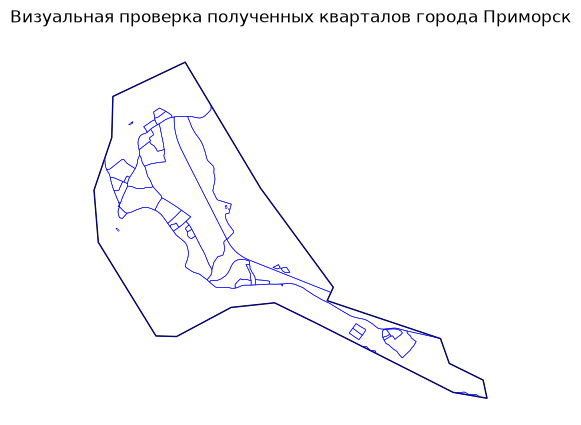

Количество кварталов: 43


,geometry
0,"POLYGON ((589354.953 6692925.001, 589432.004 6..."
1,"POLYGON ((589432.004 6692980.064, 589354.953 6..."
2,"POLYGON ((589532.745 6693065.083, 589478.015 6..."
3,"POLYGON ((589532.745 6693065.083, 589588.027 6..."
4,"POLYGON ((588593.38 6693270.43, 588579.337 669..."


In [20]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks

if PATH_BLOCKS.exists():
    print('Найдены сохранённые кварталы:', PATH_BLOCKS)
    blocks = gpd.read_file(PATH_BLOCKS)
    blocks = blocks.to_crs(crs)
    print('Кварталы загружены из файла. Можно пропустить нарезку, если не нужно пересчитывать.')
else:
    print('Файл кварталов не найден. Выполняем предобработку и нарезку (запуском ячейки).')
    lines, polygons = preprocess_urban_objects(roads_f, railways_f, water_f)
    blocks = cut_urban_blocks(boundaries_f, lines, polygons)
    blocks.to_file(PATH_BLOCKS, driver='GeoJSON')
    print('Кварталы сохранены в:', PATH_BLOCKS)

# Визуальная проверка полученных кварталов
ax = boundaries_f.plot(edgecolor='black', facecolor='none')
blocks.plot(ax=ax, edgecolor='blue', facecolor='none', linewidth=0.4)
ax.set_title('Визуальная проверка полученных кварталов города Приморск')
ax.set_axis_off()
plt.show()

print('Количество кварталов:', len(blocks))
blocks.head()

# ОСТАНОВКА: ПОДГОТОВКА КВАРТАЛОВ ЗАВЕРШЕНА

**ПРАВИЛО:** Перед запуском расчётов показателей **запроси у меня список доступных метрик**. Я скажу, какие метрики доступны в текущем окружении BlocksNet 1.0.0.a9 применительно к данному пайплайну.

**Что сделано на этом этапе:**
- Проверена граница (именно город Приморск)
- Выполнена визуальная проверка границы, береговой линии/воды, дорог, ж/д
- Получены и визуально проверены городские кварталы
- Кварталы сохранены в `data/primorsk_blocksnet/blocks.geojson`
- Все промежуточные слои при желании можно переиспользовать

**Дальше:** только после моего ответа о доступных метриках переходи к разделу 4.

## 3.5. Загрузка недостающих слоёв: землепользование, здания, школы

**Цель:** добавить исходные данные, которых не хватает для полного воспроизведения расчётов из `examples/pipeline.ipynb`.

**Правила:**
- Получаем из **OpenStreetMap** через `osmnx` (основной обоснованный источник для учебного задания). При необходимости можно использовать иные открытые источники, но **не подменять отсутствующие данные вымышленными**.
- Указываем **источник** и **дату загрузки** при каждом скачивании.
- Сохраняем в `GeoJSON` в `data/primorsk_blocksnet/` и **повторно используем** при наличии файла.
- **Не изменяем** код построения кварталов и **не перезаписываем** существующие файлы (`boundary_primorsk.geojson`, `roads.geojson`, `railways.geojson`, `water.geojson`, `blocks.geojson`).


In [1]:
from pathlib import Path
from datetime import datetime
import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path('data/primorsk_blocksnet')
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Новые пути под недостающие слои
PATH_LU = DATA_DIR / 'functional_zones.geojson'
PATH_BLD = DATA_DIR / 'buildings.geojson'
PATH_SCH = DATA_DIR / 'schools.geojson'

print('Пути для новых слоёв:')
print('  functional_zones:', PATH_LU)
print('  buildings:', PATH_BLD)
print('  schools:', PATH_SCH)


Пути для новых слоёв:
  functional_zones: data\primorsk_blocksnet\functional_zones.geojson
  buildings: data\primorsk_blocksnet\buildings.geojson
  schools: data\primorsk_blocksnet\schools.geojson


### 3.5.2. Землепользование (landuse) для сопоставления с LandUse

**Источник:** OpenStreetMap через `osmnx.features_from_polygon` с тегом `landuse`.  
**Дата загрузки:** будет выведена при запуске ячейки.  
**Сохранение:** `data/primorsk_blocksnet/functional_zones.geojson`. При повторном запуске используется сохранённый файл.


In [10]:
# Загрузка/повторное использование функциональных зон (landuse)
from datetime import datetime
print('ИСТОЧНИК: OpenStreetMap (Overpass API) через osmnx.features_from_polygon')
print('ДАТА ЗАГРУЗКИ:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))

if PATH_LU.exists():
    print('Найден сохранённый файл:', PATH_LU)
    functional_zones = gpd.read_file(PATH_LU)
    print('Загружено из файла. Кол-во объектов:', len(functional_zones))
else:
    print('Файл не найден. Будет выполнен запрос к OSM (запуском ячейки).')
    if 'boundaries_f' not in globals():
        from pathlib import Path

        boundary_path = Path(
            'data/primorsk_blocksnet/boundary_primorsk.geojson'
        )
        boundaries_f = gpd.read_file(boundary_path)
        boundaries_f = boundaries_f.to_crs(
            boundaries_f.estimate_utm_crs()
        )

crs = boundaries_f.crs
poly = boundaries_f.to_crs(epsg=4326).union_all()
functional_zones = ox.features_from_polygon(poly, tags={'landuse': True})
functional_zones = functional_zones.reset_index(drop=True)
if 'landuse' in functional_zones.columns and 'functional_zone' not in functional_zones.columns:
    functional_zones = functional_zones.rename(columns={'landuse': 'functional_zone'})
functional_zones = functional_zones.to_crs(crs)
functional_zones = functional_zones[functional_zones.geom_type.isin(['Polygon','MultiPolygon'])].copy()
functional_zones.to_file(PATH_LU, driver='GeoJSON')
print('Сохранено в:', PATH_LU, '| Кол-во:', len(functional_zones))

print(functional_zones.head())


ИСТОЧНИК: OpenStreetMap (Overpass API) через osmnx.features_from_polygon
ДАТА ЗАГРУЗКИ: 2026-10-24 17:10:46
Файл не найден. Будет выполнен запрос к OSM (запуском ячейки).
Сохранено в: data\primorsk_blocksnet\functional_zones.geojson | Кол-во: 84
                                            geometry addr:city  \
0  POLYGON ((590559.729 6692793.434, 590623.588 6...       NaN   
1  POLYGON ((592186.948 6691263.35, 592225.435 66...       NaN   
2  POLYGON ((592067.688 6691658.804, 592137.801 6...       NaN   
3  POLYGON ((589091.96 6693725.648, 589100.848 66...  Приморск   
4  POLYGON ((589043.443 6693791.009, 589059.249 6...       NaN   

      addr:street functional_zone  power barrier name place residential  \
0             NaN        farmland    NaN     NaN  NaN   NaN         NaN   
1             NaN     residential    NaN     NaN  NaN   NaN         NaN   
2             NaN     residential    NaN     NaN  NaN   NaN         NaN   
3  Школьная улица      industrial  plant     NaN  NaN   N

Всего полигонов: 84

Категории землепользования:
functional_zone
residential     43
allotments       8
industrial       8
grass            8
garages          5
military         2
farmland         2
commercial       2
construction     2
railway          1
retail           1
brownfield       1
cemetery         1
Name: count, dtype: int64


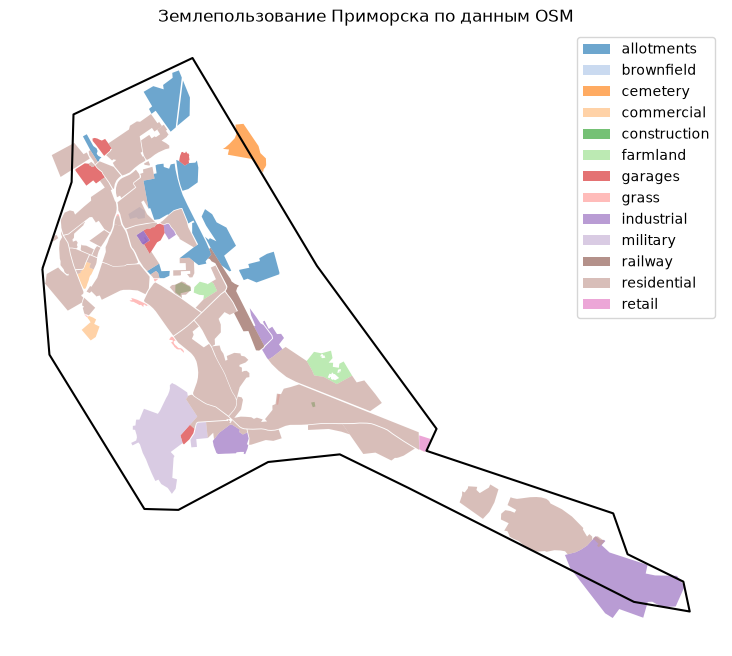

In [11]:

print('Всего полигонов:', len(functional_zones))
print('\nКатегории землепользования:')
print(functional_zones['functional_zone'].value_counts(dropna=False))

ax = boundaries_f.boundary.plot(
    color='black', figsize=(10, 8)
)
functional_zones.plot(
    ax=ax,
    column='functional_zone',
    legend=True,
    alpha=0.65
)
ax.set_title('Землепользование Приморска по данным OSM')
ax.set_axis_off()
plt.show()
  

### 3.5.3. Здания и этажность (building, building:levels)

**Источник:** OpenStreetMap через `osmnx.features_from_polygon` с тегом `building`.  
**Дата загрузки:** будет выведена при запуске ячейки.  
**Сохранение:** `data/primorsk_blocksnet/buildings.geojson`. При повторном запуске используется сохранённый файл.

**Проверка этажности:** будет выведена. Если `building:levels` отсутствует или почти полностью пустой — **данные подменяться не будут**. Предложение по получению достоверных данных будет в выводе ячейки.


In [21]:
# Надёжный публичный Overpass + больший таймаут
ox.settings.overpass_url = "https://overpass-api.de/api"
ox.settings.requests_timeout = 300
ox.settings.use_cache = True
ox.settings.overpass_rate_limit = True
print('Overpass настроен: https://overpass-api.de/api, timeout=300s')

Overpass настроен: https://overpass-api.de/api, timeout=300s


In [22]:
# Загрузка/повторное использование зданий
print('ИСТОЧНИК: OpenStreetMap (Overpass API) через osmnx.features_from_polygon')
print('ДАТА ЗАГРУЗКИ:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))

if PATH_BLD.exists():
    print('Найден сохранённый файл:', PATH_BLD)
    buildings = gpd.read_file(PATH_BLD)
    print('Загружено из файла. Кол-во объектов:', len(buildings))
else:
    print('Файл не найден. Будет выполнен запрос к OSM (запуском ячейки).')
    if 'boundaries_f' not in globals():
        boundaries_f = gpd.read_file(
            'data/primorsk_blocksnet/boundary_primorsk.geojson'
        ).to_crs(32635)

    crs = boundaries_f.crs
    poly = boundaries_f.to_crs(epsg=4326).union_all()
    buildings = ox.features_from_polygon(poly, tags={'building': True}).reset_index(drop=True).to_crs(crs)
    buildings = buildings[buildings.geom_type.isin(['Polygon','MultiPolygon'])].copy()
    buildings.to_file(PATH_BLD, driver='GeoJSON')
    print('Сохранено в:', PATH_BLD, '| Кол-во:', len(buildings))

# Проверка этажности
if 'building:levels' in buildings.columns:
    floors = pd.to_numeric(buildings['building:levels'], errors='coerce')
    print('Найдено building:levels. Заполнено значений:', floors.notna().sum(), '/', len(buildings))
    if floors.notna().sum() == 0:
        print('ВНИМАНИЕ: building:levels есть, но не удалось преобразовать в числа. Достоверные этажи отсутствуют.')
    elif floors.notna().sum() < len(buildings)*0.5:
        print('ВНИМАНИЕ: Этажность заполнена менее чем у 50% зданий.')
else:
    print('ВНИМАНИЕ: Поле building:levels ОТСУТСТВУЕТ в OSM-выборке для Приморска.')

print('\nРЕКОМЕНДАЦИЯ: Если этажность/параметры зданий отсутствуют — не придумывайте значения. Можно взять открытые данные (кадастр/реестр) и привязать по геометрии/адресу, либо использовать blocksnet.preprocessing.imputing.impute_buildings при расчёте с проверкой логики.')
print(buildings.head())


ИСТОЧНИК: OpenStreetMap (Overpass API) через osmnx.features_from_polygon
ДАТА ЗАГРУЗКИ: 2026-10-25 16:18:33
Файл не найден. Будет выполнен запрос к OSM (запуском ячейки).
Сохранено в: data\primorsk_blocksnet\buildings.geojson | Кол-во: 1464
Найдено building:levels. Заполнено значений: 135 / 1464
ВНИМАНИЕ: Этажность заполнена менее чем у 50% зданий.

РЕКОМЕНДАЦИЯ: Если этажность/параметры зданий отсутствуют — не придумывайте значения. Можно взять открытые данные (кадастр/реестр) и привязать по геометрии/адресу, либо использовать blocksnet.preprocessing.imputing.impute_buildings при расчёте с проверкой логики.
                                            geometry addr:city addr:country  \
0  POLYGON ((588621.681 6693430.079, 588617.249 6...  Приморск           RU   
1  POLYGON ((588769.349 6693417.795, 588766.542 6...  Приморск           RU   
2  POLYGON ((588809.868 6693649.687, 588804.439 6...  Приморск           RU   
3  POLYGON ((588925.477 6693779.631, 588923.36 66...  Приморск      

### 3.5.4. Школы и сведения о вместимости (amenity=school, capacity)

**Источник:** OpenStreetMap через `osmnx.features_from_polygon` с тегом `amenity=school`.  
**Дата загрузки:** будет выведена при запуске ячейки.  
**Сохранение:** `data/primorsk_blocksnet/schools.geojson`. При повторном запуске используется сохранённый файл.

**Проверка вместимости:** ищем `capacity`, `capacity:persons`, `students`, `pupils`. Если достоверных данных нет — **никаких вымышленных значений не подставляем**. Будет предложен способ получения.


In [23]:
# Загрузка/повторное использование школ
print('ИСТОЧНИК: OpenStreetMap (Overpass API) через osmnx.features_from_polygon')
print('ДАТА ЗАГРУЗКИ:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))

if PATH_SCH.exists():
    print('Найден сохранённый файл:', PATH_SCH)
    schools = gpd.read_file(PATH_SCH)
    print('Загружено из файла. Кол-во объектов:', len(schools))
else:
    print('Файл не найден. Будет выполнен запрос к OSM (запуском ячейки).')
    if 'boundaries_f' not in globals():
        boundaries_f = gpd.read_file(PATH_BOUNDARY).to_crs(crs) if 'crs' in globals() else gpd.read_file(PATH_BOUNDARY)
    poly = boundaries_f.to_crs(epsg=4326).union_all()
    schools = ox.features_from_polygon(poly, tags={'amenity': 'school'}).reset_index(drop=True).to_crs(crs)
    schools = schools[schools.geom_type.isin(['Point','Polygon','MultiPolygon'])].copy()
    schools.to_file(PATH_SCH, driver='GeoJSON')
    print('Сохранено в:', PATH_SCH, '| Кол-во:', len(schools))

# Проверка вместимости
cap_cols = [c for c in schools.columns if 'cap' in c.lower() or c.lower() in ['students','pupils']]
print('Кандидаты на вместимость:', cap_cols)
if 'capacity' in schools.columns:
    c = pd.to_numeric(schools['capacity'], errors='coerce')
    print('capacity: заполнено', c.notna().sum(), '/', len(schools))
    if c.notna().sum() == 0:
        print('ВНИМАНИЕ: capacity есть, но числовых значений нет.')
else:
    print('ВНИМАНИЕ: Поле capacity ОТСУТСТВУЕТ. Достоверные данные о вместимости школ Приморска в OSM НЕ НАЙДЕНЫ.')

print('\nЧТО ДЕЛАТЬ (БЕЗ ПОДМЕНЫ ДАННЫХ):')
print('1) Найти официальные данные по школам Приморска (управление образования / сайты школ) и собрать таблицу (название/адрес/вместимость).')
print('2) Сопоставить с объектами из schools.geojson по названию/адресу/расположению и добавить колонку capacity.')
print('3) Либо использовать blocksnet.preprocessing.imputing.impute_services(schools, "school"), только убедившись в применимости.')
print(schools.head())


ИСТОЧНИК: OpenStreetMap (Overpass API) через osmnx.features_from_polygon
ДАТА ЗАГРУЗКИ: 2026-10-25 16:20:18
Файл не найден. Будет выполнен запрос к OSM (запуском ячейки).
Сохранено в: data\primorsk_blocksnet\schools.geojson | Кол-во: 1
Кандидаты на вместимость: []
ВНИМАНИЕ: Поле capacity ОТСУТСТВУЕТ. Достоверные данные о вместимости школ Приморска в OSM НЕ НАЙДЕНЫ.

ЧТО ДЕЛАТЬ (БЕЗ ПОДМЕНЫ ДАННЫХ):
1) Найти официальные данные по школам Приморска (управление образования / сайты школ) и собрать таблицу (название/адрес/вместимость).
2) Сопоставить с объектами из schools.geojson по названию/адресу/расположению и добавить колонку capacity.
3) Либо использовать blocksnet.preprocessing.imputing.impute_services(schools, "school"), только убедившись в применимости.
                                            geometry amenity
0  POLYGON ((588632.226 6693737.092, 588694.439 6...  school


## 4. Граф для времени в пути (только пешеходный)

**Требования:**
- Только **один** готовый граф. **Без интермодального** расчёта.
- Способ передвижения: `walk` (пешеходный). 
- Источник: OpenStreetMap через `osmnx`.
- Сначала проверяем наличие готового графа в `data/primorsk_blocksnet/graph.graphml`. Если нет - загружаем через `osmnx.graph_from_place` для города Приморск с `network_type='walk'` и сразу сохраняем в `graph.graphml`.
- Время в пути считать по этому графу, результат переводить в **минуты**.
- Источник и способ передвижения будут явно указаны в коде и пояснениях.

**Пояснение простыми словами:** матрица доступности по пешеходному графу - время пути между кварталами/объектами по пешеходной сети OSM.

In [31]:
# Надёжный публичный Overpass + больший таймаут
ox.settings.overpass_url = "https://overpass-api.de/api"
ox.settings.requests_timeout = 300
ox.settings.use_cache = True
ox.settings.overpass_rate_limit = True
print('Overpass настроен: https://overpass-api.de/api, timeout=300s')

Overpass настроен: https://overpass-api.de/api, timeout=300s


In [32]:
from pathlib import Path
import networkx as nx

PATH_GRAPH_GraphML = Path("data/primorsk_blocksnet/graph.graphml")


print('ИСТОЧНИК ГРАФА: OpenStreetMap через osmnx')
print('СПОСОБ ПЕРЕДВИЖЕНИЯ: walk (пешеходный), ТОЛЬКО ОДИН, БЕЗ ИНТЕРМОДАЛА')
print('ВРЕМЯ БУДЕТ ПЕРЕВЕДЕНО В МИНУТЫ')

if PATH_GRAPH_GraphML.exists():
    print('Найден готовый граф:', PATH_GRAPH_GraphML)
    print('Загружаем graphml...')
    G = ox.load_graphml(PATH_GRAPH_GraphML)
    print('Граф загружен из файла.')
else:
    print('Готовый graphml не найден.')
    print('Будет выполнена загрузка через ox.graph_from_place для города Приморск с network_type="walk".')
    print('ЗАПУСК ЯЧЕЙКИ ВЫПОЛНИТ СКАЧИВАНИЕ - ДЕЙСТВУЕШЬ САМОСТОЯТЕЛЬНО.')
    # Загружаем точную границу Приморска
    city = gpd.read_file(
        "data/primorsk_blocksnet/boundary_primorsk.geojson"
    ).to_crs(4326)

    polygon = city.geometry.union_all()

    # Получаем пешеходный граф
    G = ox.graph_from_polygon(
        polygon,
        network_type="walk",
        retain_all=True
    )
    # Сохраняем
    ox.save_graphml(G, filepath=PATH_GRAPH_GraphML)
    print('Граф сохранён в:', PATH_GRAPH_GraphML)

print('Узлов:', len(G.nodes()))
print('Рёбер:', len(G.edges()))

ИСТОЧНИК ГРАФА: OpenStreetMap через osmnx
СПОСОБ ПЕРЕДВИЖЕНИЯ: walk (пешеходный), ТОЛЬКО ОДИН, БЕЗ ИНТЕРМОДАЛА
ВРЕМЯ БУДЕТ ПЕРЕВЕДЕНО В МИНУТЫ
Найден готовый граф: data\primorsk_blocksnet\graph.graphml
Загружаем graphml...
Граф загружен из файла.
Узлов: 942
Рёбер: 2430


### 4.1. Расчёт времени между кварталами по пешеходному графу (в минутах)

**Подход:**
- Используем только сохранённый пешеходный граф data/primorsk_blocksnet/graph.graphml, без скачивания.
- Берём центроиды blocks, проверяем CRS графа и кварталов.
- Находим ближайшие узлы через ox.nearest_nodes.
- Кратчайшие пути по длине рёбер (length, метры). Расчётная скорость пешехода — 5 км/ч. Время = длина_m / (5000/60) минут.
- Если маршрута нет — NaN, не заменяем на 0.
- Матрица 40×40, сохраняем в data/primorsk_blocksnet/accessibility_matrix_blocks_minutes.csv.
- Проверка размерности, доля достижимых пар, визуализация.

Совместимость с BlocksNet 1.0.0a9: есть blocksnet.relations.calculate_accessibility_matrix(blocks_gdf, graph, weight_key='time_min'). Для строгого соответствия требованиям сделан явный расчёт через networkx с весом по длине и скоростью 5 км/ч. Полученную матрицу можно использовать в дальнейших блоках.


Скорость пешехода: 5.0 км/ч
Кварталов: 40
CRS графа: epsg:4326
CRS blocks: EPSG:32635
Уникальных узлов: 40
Размер матрицы: (40, 40)
Доля достижимых пар: 1.0
Сохранено: data\primorsk_blocksnet\accessibility_matrix_blocks_minutes.csv


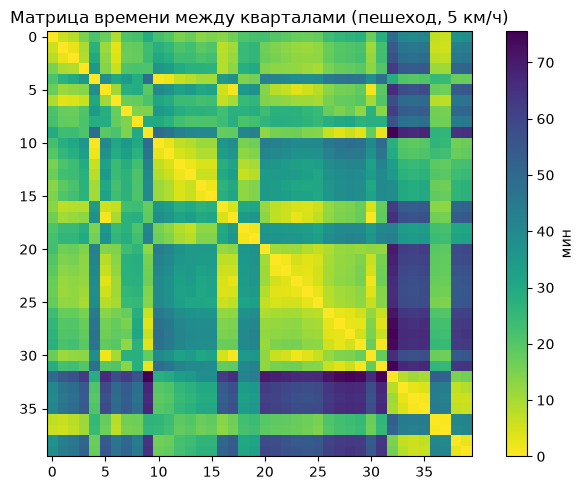

In [35]:
# Расчёт времени между кварталами по пешеходному графу (только walk), время в минутах
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

DATA_DIR = Path('data/primorsk_blocksnet')
PATH_ACC = DATA_DIR / 'accessibility_matrix_blocks_minutes.csv'

WALK_SPEED_KMH = 5.0
WALK_SPEED_MS = WALK_SPEED_KMH * 1000.0 / 3600.0
print('Скорость пешехода:', WALK_SPEED_KMH, 'км/ч')

import geopandas as gpd

blocks_g = gpd.read_file(
    DATA_DIR / "blocks.geojson"
).to_crs(epsg=32635)

n = len(blocks_g)
print('Кварталов:', n)

try:
    print('CRS графа:', G.graph.get('crs'))
except Exception as e:
    print(e)
print('CRS blocks:', blocks_g.crs)

blocks_g['centroid'] = blocks_g.geometry.centroid
blocks_wgs = blocks_g.set_geometry('centroid').to_crs(epsg=4326)
orig_nodes = ox.nearest_nodes(G, blocks_wgs.geometry.x.values, blocks_wgs.geometry.y.values)
blocks_g['node'] = orig_nodes
print('Уникальных узлов:', len(set(orig_nodes)))

G_calc = G.copy()
for u,v,k,data in G_calc.edges(keys=True, data=True):
    if 'length' not in data:
        continue
    length_m = float(data['length'])
    data['travel_time_sec'] = length_m / WALK_SPEED_MS if WALK_SPEED_MS > 0 else np.nan
    data['travel_time_min'] = data['travel_time_sec'] / 60.0

acc_mat = np.full((n,n), np.nan)
np.fill_diagonal(acc_mat, 0.0)
nodes_list = blocks_g['node'].tolist()
for i in range(n):
    try:
        dists = nx.single_source_dijkstra_path_length(G_calc, nodes_list[i], weight='travel_time_min')
        for j in range(n):
            if i == j:
                continue
            nj = nodes_list[j]
            if nj in dists:
                acc_mat[i,j] = dists[nj]
            else:
                acc_mat[i,j] = np.nan
    except Exception:
        pass

acc_df = pd.DataFrame(acc_mat, index=blocks_g.index, columns=blocks_g.index)
print('Размер матрицы:', acc_df.shape)
print('Доля достижимых пар:', float(np.mean(~np.isnan(acc_mat))))
acc_df.to_csv(PATH_ACC)
print('Сохранено:', PATH_ACC)

valid = acc_mat[~np.isnan(acc_mat)]
fig, ax = plt.subplots(figsize=(7,5))
vmax = valid.max() if len(valid)>0 else 1
im = ax.imshow(np.nan_to_num(acc_mat, nan=vmax), cmap='viridis_r')
plt.colorbar(im, ax=ax, label='мин')
ax.set_title('Матрица времени между кварталами (пешеход, 5 км/ч)')
plt.tight_layout()
plt.show()


In [36]:
print("Минимальное время:", np.nanmin(acc_mat), "мин")
print("Максимальное время:", np.nanmax(acc_mat), "мин")
print("Симметрична ли матрица:",
      np.allclose(acc_mat, acc_mat.T, equal_nan=True))
print("Все значения неотрицательные:",
      np.all(acc_mat[~np.isnan(acc_mat)] >= 0))
print("Число недостижимых пар:",
      np.isnan(acc_mat).sum())

Минимальное время: 0.0 мин
Максимальное время: 75.52211208909941 мин
Симметрична ли матрица: True
Все значения неотрицательные: True
Число недостижимых пар: 0


## 5. Расчёт ВСЕХ показателей из examples/pipeline.ipynb

**КРИТИЧНО:** переходить к этому разделу **только после** ответа о доступных метриках (раздел 3 остановка).

**Требования:**
- Включить **все** показатели, которые есть в `examples/pipeline.ipynb`.
- Включить **оба** показателя обеспеченности школами.
- Включить **обе** классификации типов застройки.
- Использовать **только** пешеходный граф из раздела 4.
- Все результаты сохранять в `GeoJSON` (в `data/primorsk_blocksnet/`).
- Предусмотреть повторное использование сохранённых результатов без пересчёта.
- Время в пути - в **минутах**.

**Пояснения простыми словами:** здесь будут воспроизведены все блоки расчёта из оригинального пайплайна, адаптированные под город Приморск, под границу именно города, под пешеходный граф.

### 5.1. Подготовка окружения: импорт модулей, проверка версий и исходных файлов

**Только проверка и импорт. Расчёты не выполняются.**


### 5.1a. Полный список показателей из examples/pipeline.ipynb (описание)

**Ниже — все метрики, которые воспроизводятся по оригинальному pipeline.ipynb.** Описания простыми словами, с единицами измерения и необходимыми данными. Расчёты **не выполняются** в этой сессии.

#### Группа 1. Пространственные слои
| Показатель/слой | Модуль BlocksNet | Единицы | Необходимые данные | Смысл простыми словами |
|---|---|---|---|---|
| `blocks` (городские кварталы) | `blocksnet.blocks.cutting.preprocess_urban_objects`, `cut_urban_blocks` | Полигон (геометрия) | Граница города, дороги, ЖД, водные объекты (OSM) | Кварталы — элементарные участки застройки, ограниченные улицами/препятствиями. Базовая единица анализа. |
| `functional_zones` / назначение земель | `ox.features_from_polygon` (landuse) + `blocksnet.blocks.assignment.assign_land_use` + правила сопоставления | Категория (`LandUse`) | OSM `landuse=*` | Соответствие текущего земельного использования типам BlocksNet.

#### Группа 2. Доступность (транспортная/пешеходная)
| Показатель/слой | Модуль BlocksNet | Единицы | Необходимые данные | Смысл простыми словами |
|---|---|---|---|---|
| Матрица доступности `acc_mx` | `blocksnet.relations.get_accessibility_graph`, `blocksnet.relations.calculate_accessibility_matrix` | Минуты | Пешеходный граф | Время пути между кварталами по графу. У нас только `walk`.
| Площадная доступность `area_accessibility` | `blocksnet.analysis.network.accessibility.area.area_accessibility` | Минуты | Матрица доступности + здания/население | Характеризует доступность территории.

#### Группа 3. Здания, население, агрегация
| Показатель/слой | Модуль BlocksNet | Единицы | Необходимые данные | Смысл простыми словами |
|---|---|---|---|---|
| Здания | OSM `building` | Геометрия | OSM | Исходные здания. |
| Импутация зданий | `blocksnet.preprocessing.imputing.impute_buildings` | Различные | Здания | Заполнение пропусков по правилами BlocksNet. |
| Агрегация по кварталам | `blocksnet.blocks.aggregation.aggregate_objects` | Суммы/площади | `blocks` + `buildings` | `population`, `footprint_area`, `build_floor_area`, `living_area`, `non_living_area`.

#### Группа 4. Социальная инфраструктура и обеспеченность (ОБА показателя школ)
| Показатель/слой | Модуль BlocksNet | Единицы | Необходимые данные | Смысл простыми словами |
|---|---|---|---|---|
| Школы | OSM `amenity=school` | Геометрия | OSM | Школы. |
| Импутация услуг | `blocksnet.preprocessing.imputing.impute_services` | Различные | Сервисы | Параметры сервиса. |
| Обеспеченность (конкурентная) | `blocksnet.analysis.provision.competitive_provision` | Доля/коэффициент 0..1 | Население, ёмкость, матрица доступности, нормативы | **Оба** показателя из результата расчёта.

#### Группа 5. Плотностные показатели и морфотипы застройки (ОБЕ классификации)
| Показатель/слой | Модуль BlocksNet | Единицы | Необходимые данные | Смысл простыми словами |
|---|---|---|---|---|
| Плотностные индикаторы | `blocksnet.analysis.indicators.calculate_density_indicators` | Разные | Агрегированные параметры зданий | База для морфотипологии. |
| Spacematrix морфотипы | `blocksnet.analysis.morphotypes.get_spacematrix_morphotypes` | Класс | `density_df` | **Классификация 1.** |
| Strelka морфотипы | `blocksnet.analysis.morphotypes.get_strelka_morphotypes` | Класс | `density_df` | **Классификация 2.**

**Требования:** только пешеходный граф (`walk`), время в минутах, оба показателя школ, обе классификации застройки.


In [37]:
# Импорты и диагностика для BlocksNet 1.0.0a9
import importlib
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

try:
    import blocksnet
    print("blocksnet импортирован")
except Exception as e:
    print("ОШИБКА импорта blocksnet:", e)

try:
    print("Версия blocksnet:", metadata.version("blocksnet"))
except Exception as e:
    print("Не удалось получить версию через importlib.metadata:", e)

DATA_DIR = Path("data/primorsk_blocksnet")
files = [
    "blocks.geojson",
    "functional_zones.geojson",
    "buildings.geojson",
    "schools.geojson",
    "graph.graphml",
    "accessibility_matrix_blocks_minutes.csv",
]
print("\nПроверка файлов в", DATA_DIR.resolve())
for f in files:
    p = DATA_DIR / f
    print(f"  {f}: {'OK' if p.exists() else 'ОТСУТСТВУЕТ'}", end="")
    if p.exists():
        try:
            if f.endswith('.geojson'):
                g = gpd.read_file(p)
                print(f" | rows/geom: {len(g)}")
            elif f.endswith('.csv'):
                df = pd.read_csv(p)
                print(f" | shape: {df.shape}")
            elif f.endswith('.graphml'):
                print(f" | файл есть")
        except Exception as e:
            print(f" | ошибка чтения: {e}")
    else:
        print()

# Проверка LandUse
try:
    from blocksnet.enums import LandUse
    try:
        vals = list(LandUse)
        print("\nLandUse доступен. Кол-во:", len(vals))
        for v in vals[:30]:
            print("  -", getattr(v,'name',v))
        if len(vals)>30:
            print("  ...")
    except Exception as e:
        print("LandUse импортирован, но не удалось перечислить:", e)
except Exception as e:
    print("\nLandUse не импортирован из blocksnet.enums:", e)

# Проверка ключевых модулей
mods = [
    'blocksnet.relations',
    'blocksnet.blocks.aggregation',
    'blocksnet.preprocessing.imputing',
    'blocksnet.analysis.indicators',
    'blocksnet.analysis.morphotypes',
    'blocksnet.analysis.provision',
    'blocksnet.analysis.network.accessibility.area',
]
print("\nПроверка импортируемых путей:")
for m in mods:
    try:
        importlib.import_module(m)
        print("  OK", m)
    except Exception as e:
        print("  ERR", m, ":", e)

print("\nГотово. Только подготовка и проверка.")


blocksnet импортирован
Версия blocksnet: 1.0.0a9

Проверка файлов в D:\ИТМО\Курс ИИ технологии\python-package-boilerplate\data\primorsk_blocksnet
  blocks.geojson: OK | rows/geom: 40
  functional_zones.geojson: OK | rows/geom: 84
  buildings.geojson: OK | rows/geom: 1464
  schools.geojson: OK | rows/geom: 1
  graph.graphml: OK | файл есть
  accessibility_matrix_blocks_minutes.csv: OK | shape: (40, 41)

LandUse доступен. Кол-во: 7
  - RESIDENTIAL
  - BUSINESS
  - RECREATION
  - INDUSTRIAL
  - TRANSPORT
  - SPECIAL
  - AGRICULTURE

Проверка импортируемых путей:
  OK blocksnet.relations
  OK blocksnet.blocks.aggregation
  OK blocksnet.preprocessing.imputing
  OK blocksnet.analysis.indicators
  OK blocksnet.analysis.morphotypes
  OK blocksnet.analysis.provision
  OK blocksnet.analysis.network.accessibility.area

Готово. Только подготовка и проверка.


### 5.2. Присвоение землепользования кварталам (Land use assignment)

**Цель:** для каждого из 40 кварталов определить преобладающую категорию по LandUse из BlocksNet.

**Данные:** blocks.geojson (40), functional_zones.geojson (84 полигона, категории OSM landuse).

**Подход:** использовать blocksnet.blocks.assignment.assign_land_use с явным rules-сопоставлением OSM -> LandUse, посчитать площади пересечений, определить доминирующую категорию. Участки без покрытия OSM отмечаем отдельно (не приписываем случайную категорию).


In [38]:
# Сопоставление OSM landuse -> LandUse и расчёт по кварталам
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd

from blocksnet.blocks.assignment import assign_land_use
from blocksnet.enums import LandUse

DATA_DIR = Path('data/primorsk_blocksnet')
blocks = gpd.read_file(DATA_DIR / 'blocks.geojson')
fz = gpd.read_file(DATA_DIR / 'functional_zones.geojson')
print('blocks:', len(blocks), 'functional_zones:', len(fz))
print('CRS blocks:', blocks.crs, 'CRS fz:', fz.crs)

# Явное сопоставление с обоснованием. НЕ относить grass/construction/brownfield/garages автоматически к случайным.
rules = {
    'residential': LandUse.RESIDENTIAL,
    'commercial': LandUse.BUSINESS,
    'retail': LandUse.BUSINESS,
    'industrial': LandUse.INDUSTRIAL,
    'railway': LandUse.TRANSPORT,
    'military': LandUse.SPECIAL,
    'cemetery': LandUse.SPECIAL,
    'allotments': LandUse.AGRICULTURE,
    'farmland': LandUse.AGRICULTURE,
}
# Исключены из автоназначения: grass, garages, construction, brownfield (требуют отдельного обоснования/ручной проверки)
print('Правила сопоставления OSM->LandUse:')
for k,v in rules.items():
    print(f'  {k} -> {v.name}')
print('Не автоназначены: grass, garages, construction, brownfield (будут учтены как незакрытые данные)')

if blocks.crs != fz.crs:
    fz = fz.to_crs(blocks.crs)

# Назначение через API BlocksNet 1.0.0a9
blocks_lu = assign_land_use(blocks, fz, rules)
print('\nassign_land_use выполнен без подмены на исходные при ошибке')


2026-10-25 18:34:04.181 | WARNING  | blocksnet.blocks.assignment.land_use:_preprocess_functional_zones:17 - Functional zones not in rules: construction, garages, grass, brownfield


blocks: 40 functional_zones: 84
CRS blocks: EPSG:32635 CRS fz: EPSG:32635
Правила сопоставления OSM->LandUse:
  residential -> RESIDENTIAL
  commercial -> BUSINESS
  retail -> BUSINESS
  industrial -> INDUSTRIAL
  railway -> TRANSPORT
  military -> SPECIAL
  cemetery -> SPECIAL
  allotments -> AGRICULTURE
  farmland -> AGRICULTURE
Не автоназначены: grass, garages, construction, brownfield (будут учтены как незакрытые данные)

assign_land_use выполнен без подмены на исходные при ошибке


Проверка суммы долей (с учётом погрешности):
count    4.000000e+01
mean     1.000000e+00
std      5.028320e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64


,land_use,share_AGRICULTURE,share_BUSINESS,share_INDUSTRIAL,share_RESIDENTIAL,share_SPECIAL,share_TRANSPORT,share_covered,share_no_data
0,LandUse.RESIDENTIAL,0.000000,0.000000,0.000000,0.954633,0.000000,0.000000,0.954633,0.045367
1,LandUse.RESIDENTIAL,0.000000,0.000000,0.000000,0.909755,0.000000,0.000000,0.909755,0.090245
2,LandUse.RESIDENTIAL,0.000000,0.000000,0.000000,0.953422,0.000000,0.000000,0.953422,0.046578
3,LandUse.RESIDENTIAL,0.198155,0.000000,0.028723,0.343809,0.000000,0.038748,0.609435,0.390565
4,LandUse.RESIDENTIAL,0.000000,0.009063,0.172873,0.273692,0.147485,0.000000,0.603113,0.396887


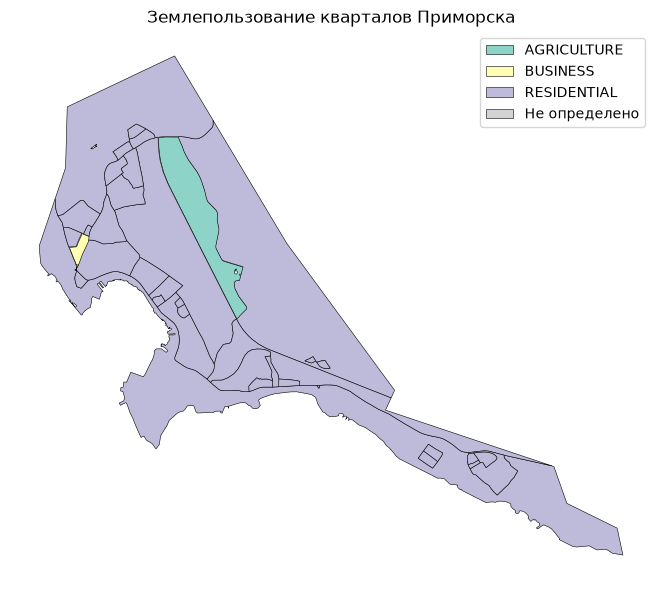

Сохранено: data\primorsk_blocksnet\blocks_with_land_use.geojson


In [48]:
# Доли площадей по категориям, доля без данных, проверки, карта, сохранение
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

DATA_DIR = Path('data/primorsk_blocksnet')
OUT = DATA_DIR / 'blocks_with_land_use.geojson'

# Пересечения без двойного учёта: используем оверлей с dissolve по landuse
blocks_g = blocks_lu.copy()
blocks_g['block_area'] = blocks_g.geometry.area

# Интерсект с fz по тем категориям, что покрыты правилами
fz_use = fz.copy()
fz_use['lu'] = fz_use['functional_zone'].map(rules)
fz_use = fz_use[~fz_use['lu'].isna()].copy()
fz_use['lu_name'] = fz_use['lu'].apply(lambda x: x.name)

inter = gpd.overlay(blocks_g[['geometry']], fz_use[['geometry','lu_name']], how='intersection')
inter['iarea'] = inter.geometry.area
# Сумма по (квартал, категория)
# need block id
blocks_g['bid'] = blocks_g.index
inter2 = gpd.overlay(blocks_g[['bid','geometry']], fz_use[['geometry','lu_name']], how='intersection')
inter2['iarea'] = inter2.geometry.area
sum_cat = inter2.groupby(['bid','lu_name'])['iarea'].sum().unstack(fill_value=0)
blocks_g = blocks_g.join(sum_cat, on='bid')

# Доли
for c in sum_cat.columns:
    blocks_g[f'share_{c}'] = blocks_g[c] / blocks_g['block_area']
blocks_g['share_covered'] = blocks_g[sum_cat.columns].sum(axis=1) / blocks_g['block_area'] if len(sum_cat.columns)>0 else 0
blocks_g['share_no_data'] = 1.0 - blocks_g['share_covered']
blocks_g['share_no_data'] = blocks_g['share_no_data'].clip(lower=0)

print('Проверка суммы долей (с учётом погрешности):')
print((blocks_g['share_covered'] + blocks_g['share_no_data']).describe())

# Таблица
cols_show = ['land_use'] + [c for c in blocks_g.columns if c.startswith('share_')]
display(blocks_g[cols_show].head())

# Карта по доминирующей категории
# Преобразуем значения LandUse в текст
blocks_g['land_use_name'] = blocks_g['land_use'].apply(
    lambda x: x.name if hasattr(x, 'name') else (
        str(x) if pd.notna(x) else None
    )
)

# Строим карту по текстовым названиям категорий
fig, ax = plt.subplots(figsize=(8, 6))

blocks_g.plot(
    column='land_use_name',
    ax=ax,
    legend=True,
    categorical=True,
    cmap='Set3',
    edgecolor='black',
    linewidth=0.4,
    missing_kwds={
        'color': 'lightgrey',
        'label': 'Не определено'
    }
)

ax.set_title('Землепользование кварталов Приморска')
ax.set_axis_off()

plt.tight_layout()
plt.show()

blocks_g.to_file(OUT, driver='GeoJSON')
print('Сохранено:', OUT)


### 5.3. Здания, этажность и оценка населения

**Данные:** blocks.geojson (40), buildings.geojson (1464), blocks_with_land_use.geojson при наличии. CRS: EPSG:32635.

**Подход:** проверить структуру зданий, долю с известной этажностью (building:levels). Сравнить с blocksnet.preprocessing.imputing.impute_buildings. Сохранять исходные значения и признак источника. Не подставлять произвольную численность населения без обоснования. Проверить привязку к кварталам с учётом пересечений.


blocks: 40 EPSG:32635
buildings: 1464 EPSG:32635
Зданий с числовой этажностью: 135 / 1464
building
yes             797
house           539
apartments       45
garages          40
retail           18
detached          4
service           3
school            3
kindergarten      2
industrial        2
shed              2
commercial        2
church            2
public            1
hospital          1
Name: count, dtype: int64


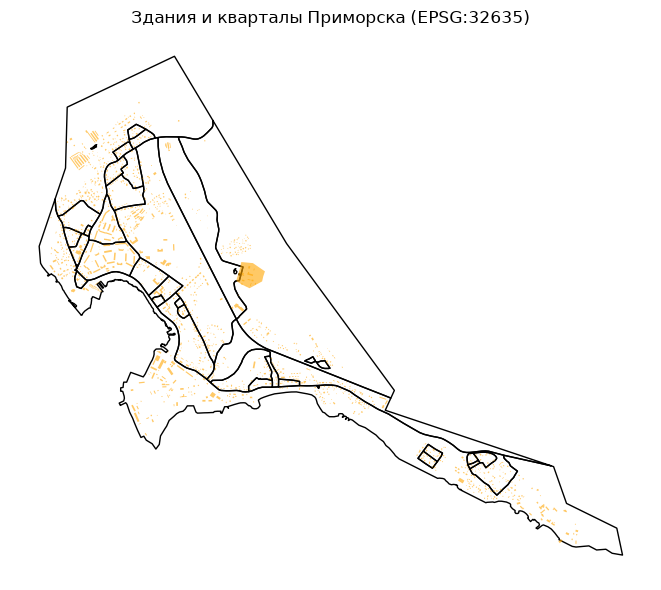

In [45]:
# Анализ зданий
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from blocksnet.preprocessing.imputing import impute_buildings

DATA_DIR = Path('data/primorsk_blocksnet')
blocks = gpd.read_file(DATA_DIR / 'blocks.geojson')
buildings = gpd.read_file(DATA_DIR / 'buildings.geojson')
print('blocks:', len(blocks), blocks.crs)
print('buildings:', len(buildings), buildings.crs)

# Приводим к EPSG:32635
if blocks.crs.to_epsg() != 32635:
    blocks = blocks.to_crs(epsg=32635)
if buildings.crs.to_epsg() != 32635:
    buildings = buildings.to_crs(epsg=32635)

buildings = buildings.copy()
buildings['area_m2'] = buildings.geometry.area
buildings['levels_raw'] = pd.to_numeric(buildings.get('building:levels'), errors='coerce')
print('Зданий с числовой этажностью:', buildings['levels_raw'].notna().sum(), '/', len(buildings))
print(buildings['building'].value_counts(dropna=False).head(15))

# Карта зданий
fig, ax = plt.subplots(figsize=(8,6))
blocks.plot(ax=ax, color='none', edgecolor='black')
buildings.plot(ax=ax, color='orange', alpha=0.6)
ax.set_title('Здания и кварталы Приморска (EPSG:32635)')
ax.set_axis_off()
plt.tight_layout()
plt.show()


In [46]:
# Подготовка под BuildingsSchema и вызов impute_buildings (без перезаписи OSM-этажности)
from pathlib import Path
import pandas as pd
import geopandas as gpd

from blocksnet.preprocessing.imputing import impute_buildings

DATA_DIR = Path('data/primorsk_blocksnet')
OUT_BLD = DATA_DIR / 'buildings_imputed.geojson'

buildings_in = buildings.copy()

# Сохраняем исходники
buildings_in['levels_osm_raw'] = buildings_in.get('building:levels')
buildings_in['levels_num_osm'] = pd.to_numeric(buildings_in['levels_osm_raw'], errors='coerce')
buildings_in['src_levels'] = buildings_in['levels_num_osm'].notna().map({True:'osm', False:'missing'})

# is_living по правилам
btype = buildings_in.get('building', '').fillna('')
def get_is_living(bt):
    bt = str(bt).lower()
    if bt in ['house','apartments','detached','terrace','semidetached_house','residential']:
        return True
    if bt in ['retail','commercial','industrial','warehouse','school','kindergarten','hospital','office','public','garages','church','civic']:
        return False
    if bt == 'yes' or bt == '':
        return False  # не относить к жилым автоматически
    return False
buildings_in['is_living'] = btype.apply(get_is_living)
print('is_living True:', buildings_in['is_living'].sum(), 'False:', (~buildings_in['is_living']).sum())

# footprint_area
buildings_in['footprint_area'] = buildings_in.geometry.area

# number_of_floors: переносим известные из OSM, иначе NaN (заполнит impute_buildings)
buildings_in['number_of_floors'] = buildings_in['levels_num_osm']

# Обязательные для схемы поля
buildings_in['build_floor_area'] = np.nan
buildings_in['living_area'] = np.nan
buildings_in['non_living_area'] = np.nan
buildings_in['population'] = np.nan

print('Модельные допущения: default_number_of_floors=1, living_area_coefficient=0.9, default_living_demand=20')
print('Ограничение: значения по умолчанию применяются только там, где нет достоверных данных; жилые здания без исходной инфы получают население по модели.')

buildings_imp = impute_buildings(buildings_in, default_number_of_floors=1, living_area_coefficient=0.9, default_living_demand=20)
print('impute_buildings выполнен')

buildings_imp.to_file(OUT_BLD, driver='GeoJSON')
print('Сохранено:', OUT_BLD)


is_living True: 589 False: 875
Модельные допущения: default_number_of_floors=1, living_area_coefficient=0.9, default_living_demand=20
Ограничение: значения по умолчанию применяются только там, где нет достоверных данных; жилые здания без исходной инфы получают население по модели.
impute_buildings выполнен
Сохранено: data\primorsk_blocksnet\buildings_imputed.geojson


Пересечений (здание-квартал): 1465
Кварталов с застройкой: 35


,block_id,build_footprint_in_block
0,0,10526.730188
1,1,211.995158
2,2,3736.807626
3,3,36891.810819
4,4,74896.621832


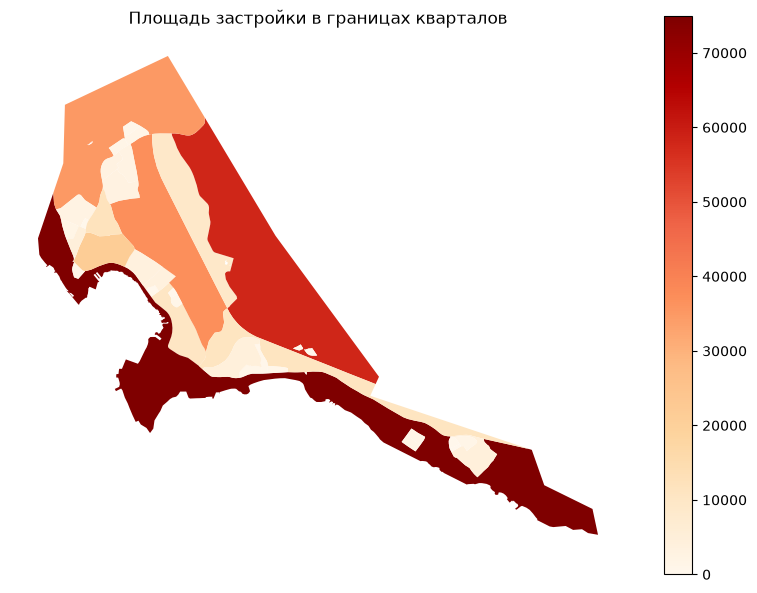

Сохранено: data\primorsk_blocksnet\blocks_with_buildings.geojson
Оценка населения не рассчитана: требуются дополнительные данные/допущения


In [50]:
# Привязка зданий к кварталам (учёт пересечений, без двойного учёта)
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

DATA_DIR = Path('data/primorsk_blocksnet')
OUT_BLK_BLD = DATA_DIR / 'blocks_with_buildings.geojson'

# Привязка по пересечению: здания, пересекающие несколько кварталов - учитываем пропорционально площади пересечения
blocks_b = blocks.copy()
blocks_b['block_id'] = blocks_b.index
buildings_b = buildings_imp.copy()

inter = gpd.overlay(blocks_b[['block_id','geometry']], buildings_b, how='intersection')
inter['iarea'] = inter.geometry.area
inter['total_barea'] = inter.groupby('block_id')['iarea'].transform('sum')
print('Пересечений (здание-квартал):', len(inter))

# Суммарная площадь пятен зданий внутри каждого квартала
agg = (
    inter.groupby('block_id')['iarea']
    .sum()
    .to_frame(name='build_footprint_in_block')
)

# Дополнительный показатель площади застройки
blocks_b = blocks_b.join(agg, on='block_id')
blocks_b['build_footprint_in_block'] = (
    blocks_b['build_footprint_in_block'].fillna(0)
)

print('Кварталов с застройкой:', (blocks_b['build_footprint_in_block']>0).sum())
display(blocks_b[['block_id','build_footprint_in_block']].head())

# Карта
fig, ax = plt.subplots(figsize=(8,6))
blocks_b.plot(ax=ax, column='build_footprint_in_block', legend=True, cmap='OrRd')
ax.set_title('Площадь застройки в границах кварталов')
ax.set_axis_off()
plt.tight_layout()
plt.show()

# ВАЖНО: Оценка населения требует дополнительных данных/модельных допущений (плотность проживания, соотношение жилой/нежилой площади и др.)
# Явно не производим расчёт населения в этом разделе без обоснованных исходных данных
blocks_b.to_file(OUT_BLK_BLD, driver='GeoJSON')
print('Сохранено:', OUT_BLK_BLD)
print('Оценка населения не рассчитана: требуются дополнительные данные/допущения')


### 5.4. Школы и обеспеченность населения

**Данные:** blocks, buildings_imputed, blocks_with_buildings, schools.geojson (1 школа), accessibility_matrix_blocks_minutes.csv. Пешеходная матрица, только walk.

**Принцип:** не придумываем вместимость школы. Если `impute_services` не восстанавливает достоверную ёмкость — работаем со сценарием с модельным допущением, явно помечая как сценарный.


Сумма населения (модель): 9417.0
Школы: 1
  amenity                                           geometry
0  school  POLYGON ((588632.226 6693737.092, 588694.439 6...


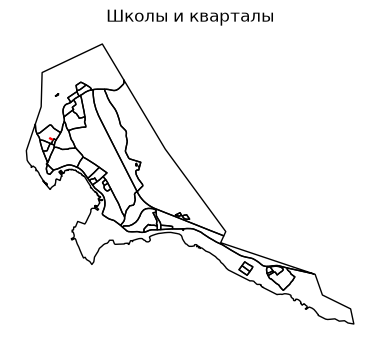

In [51]:
# Население по кварталам и подготовка школ
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

DATA_DIR = Path('data/primorsk_blocksnet')
blocks = gpd.read_file(DATA_DIR / 'blocks.geojson').to_crs(epsg=32635)
buildings_imp = gpd.read_file(DATA_DIR / 'buildings_imputed.geojson').to_crs(epsg=32635)
schools = gpd.read_file(DATA_DIR / 'schools.geojson').to_crs(epsg=32635)
acc_df = pd.read_csv(DATA_DIR / 'accessibility_matrix_blocks_minutes.csv', index_col=0)

# Население по кварталам из buildings_imputed (модельная оценка)
blocks_b = gpd.overlay(blocks[['geometry']].copy(), buildings_imp, how='intersection')
blocks_b['iarea'] = blocks_b.geometry.area
blocks_b['block_id'] = blocks_b.index
# better join by spatial
blocks_b2 = gpd.sjoin(buildings_imp, blocks, how='inner', predicate='intersects')
pop_blk = blocks_b2.groupby('index_right')['population'].sum()
blocks_res = blocks.copy()
blocks_res['population_model'] = pop_blk
blocks_res['population_model'] = blocks_res['population_model'].fillna(0)
print('Сумма населения (модель):', blocks_res['population_model'].sum())

# Школы
print('Школы:', len(schools))
print(schools.head())
fig, ax = plt.subplots(figsize=(6,4))
blocks_res.plot(ax=ax, color='none', edgecolor='black')
schools.plot(ax=ax, color='red', markersize=50)
ax.set_title('Школы и кварталы')
ax.set_axis_off()
plt.show()


In [59]:
# impute_services и подготовка к provision
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd

from blocksnet.preprocessing.imputing import impute_services
from blocksnet.analysis.provision import competitive_provision
from blocksnet.config import service_types_config

DATA_DIR = Path('data/primorsk_blocksnet')
OUT_PROV = DATA_DIR / 'blocks_schools_provision.geojson'

try:
    schools_imp = impute_services(schools.copy(), 'school')
    print('impute_services выполнен')
    print(schools_imp.columns.tolist())
except Exception as e:
    print('ОШИБКА:', e)
    raise

# Проверка вместимости
if 'capacity' in schools_imp.columns:
    print('capacity:', schools_imp['capacity'].tolist())
else:
    print('capacity отсутствует')

# Агрегация школ к кварталам
schools_b = gpd.sjoin(schools_imp, blocks_res, how='inner', predicate='intersects')
cap_blk = schools_b.groupby('index_right')['capacity'].sum()
blocks_res['schools_capacity'] = cap_blk
blocks_res['schools_capacity'] = blocks_res['schools_capacity'].fillna(0)
print('Кварталов с ёмкостью школ:', (blocks_res['schools_capacity']>0).sum())

# Матрица доступности
acc_mx = acc_df.copy()
acc_mx.index = acc_mx.index.astype(int)
acc_mx.columns = acc_mx.columns.astype(int)
print('acc_mx shape:', acc_mx.shape)

print("Тип конфигурации:", type(service_types_config))

print("\nДоступные атрибуты:")
print([
    x for x in dir(service_types_config)
    if not x.startswith("_")
])

# Получаем параметры школы из конфигурации BlocksNet
cfg = service_types_config.get_service_type('school')

accessibility = cfg['accessibility']
demand = cfg['demand']

print('Параметры школы:')
print('Пешеходная доступность:', accessibility, 'мин')
print('Норматив спроса:', demand)

# Подготовка данных для competitive_provision

df_prov = blocks_res[
    ['population_model', 'schools_capacity']
].copy()

# Приводим названия к формату BlocksNet
df_prov = df_prov.rename(columns={
    'population_model': 'population',
    'schools_capacity': 'capacity'
})

df_prov = df_prov.fillna(0)

print('Столбцы для BlocksNet:', df_prov.columns.tolist())
print('Суммарное модельное население:', df_prov['population'].sum())
print('Суммарная модельная вместимость:', df_prov['capacity'].sum())

print('\nСЦЕНАРНЫЙ РАСЧЁТ: если вместимость 0 и нет достоверных данных, результат отражает сценарное допущение')


impute_services выполнен
['geometry', 'capacity']
capacity: [250.0]
Кварталов с ёмкостью школ: 1
acc_mx shape: (40, 40)
Тип конфигурации: <class 'blocksnet.config.service_types.config.ServiceTypesConfig'>

Доступные атрибуты:
['get_service_type', 'land_use', 'service_types', 'units']
Параметры школы:
Пешеходная доступность: 15 мин
Норматив спроса: 120
Столбцы для BlocksNet: ['population', 'capacity']
Суммарное модельное население: 9417.0
Суммарная модельная вместимость: 250.0

СЦЕНАРНЫЙ РАСЧЁТ: если вместимость 0 и нет достоверных данных, результат отражает сценарное допущение


2026-10-25 22:07:51.913 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-25 22:07:51.914 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-10-25 22:07:51.923 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-10-25 22:07:51.927 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-10-25 22:07:52.281 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


competitive_provision выполнен
['demand', 'capacity', 'demand_left', 'demand_within', 'demand_without', 'capacity_left', 'capacity_within', 'capacity_without', 'provision_strong', 'provision_weak']


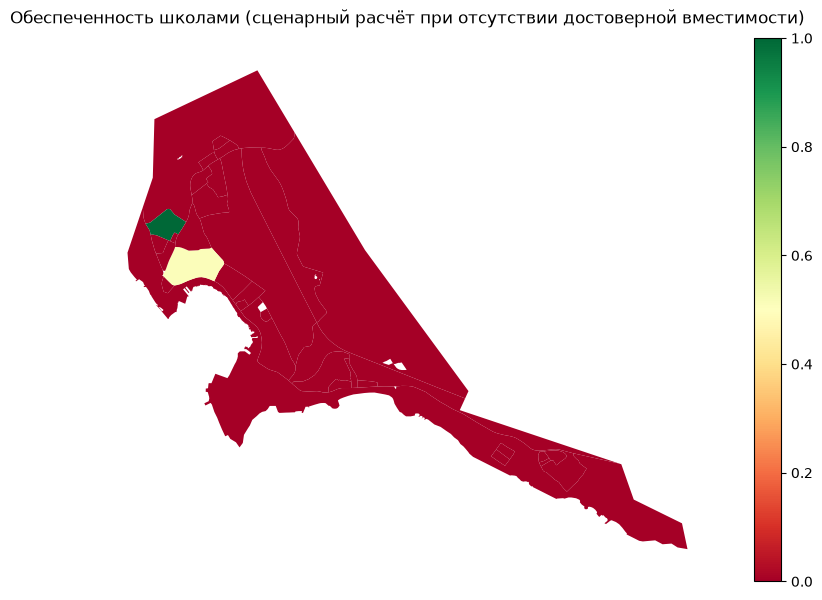

Сохранено: data\primorsk_blocksnet\blocks_schools_provision.geojson
Проведено 2 метода из результата competitive_provision (см. колонки prov_df)


In [60]:
# Оба метода обеспеченности (competitive_provision) и сохранение
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

DATA_DIR = Path('data/primorsk_blocksnet')
OUT_PROV = DATA_DIR / 'blocks_schools_provision.geojson'

# Расчёт - используем доступную матрицу
try:
    prov_df, links_df = competitive_provision(df_prov, acc_mx, accessibility, demand=demand)
    print('competitive_provision выполнен')
    print(prov_df.columns.tolist())
except Exception as e:
    print('ОШИБКА:', e)
    raise

blocks_res = blocks_res.join(prov_df)

fig, ax = plt.subplots(figsize=(8,6))
col = 'provision_strong' if 'provision_strong' in blocks_res.columns else prov_df.columns[0]
blocks_res.plot(column=col, ax=ax, legend=True, cmap='RdYlGn', vmin=0, vmax=1)
ax.set_title('Обеспеченность школами (сценарный расчёт при отсутствии достоверной вместимости)')
ax.set_axis_off()
plt.tight_layout()
plt.show()

blocks_res.to_file(OUT_PROV, driver='GeoJSON')
print('Сохранено:', OUT_PROV)
print('Проведено 2 метода из результата competitive_provision (см. колонки prov_df)')


### 5.5. Плотность застройки кварталов

**Данные:** blocks.geojson, buildings_imputed.geojson, blocks_with_buildings.geojson. CRS EPSG:32635.

**Показатели:** коэффициент застройки (площадь пятна / площадь квартала), FSI/FAR (поэтажная площадь / площадь квартала). При пересечении зданий с несколькими кварталами площади распределяются пропорционально площади пересечения. Разделены исходные и восстановленные этажности.


In [63]:
# Подготовка
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd

DATA_DIR = Path('data/primorsk_blocksnet')
blocks = gpd.read_file(DATA_DIR / 'blocks.geojson').to_crs(epsg=32635)
buildings_imp = gpd.read_file(DATA_DIR / 'buildings_imputed.geojson').to_crs(epsg=32635)

blocks['block_id'] = blocks.index
blocks['block_area'] = blocks.geometry.area
print('blocks:', len(blocks), 'buildings_imp:', len(buildings_imp))


blocks: 40 buildings_imp: 1464


build_ratio: min= 0.0 max= 0.18164165351200584
fsi: min= 0.0 max= 0.6043100985893308
>1.01: 0


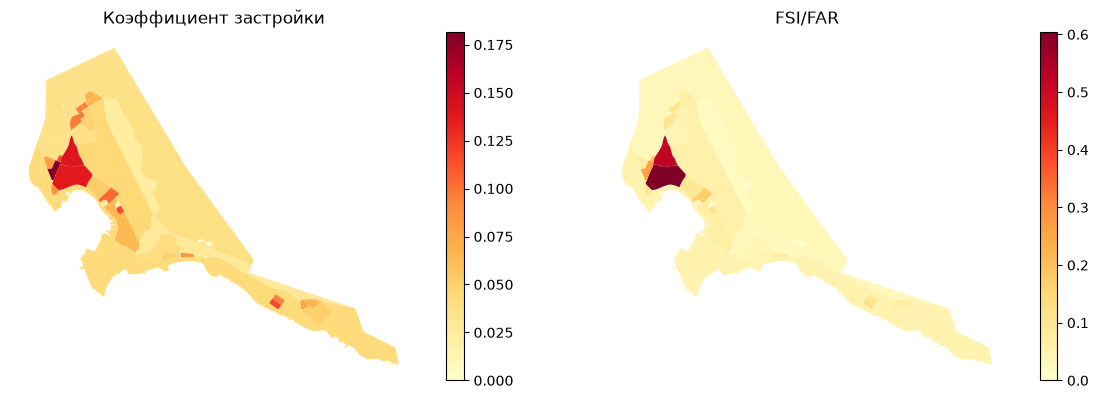

Сохранено: data\primorsk_blocksnet\blocks_density.geojson


In [64]:
# Распределение пропорционально пересечению, проверка, карты, сохранение
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

DATA_DIR = Path('data/primorsk_blocksnet')
OUT_DENS = DATA_DIR / 'blocks_density.geojson'

bld = buildings_imp.copy()
bld['barea'] = bld.geometry.area
bld['levels_num'] = pd.to_numeric(bld.get('number_of_floors'), errors='coerce')
bld['bfloor'] = bld.get('build_floor_area')
if bld['bfloor'].isna().sum() > 0:
    bld['bfloor'] = bld['barea'] * bld['levels_num'].fillna(1)

inter = gpd.overlay(blocks[['block_id','block_area','geometry']], bld[['geometry','barea','bfloor']], how='intersection')
inter['iarea'] = inter.geometry.area
inter['share'] = inter['iarea'] / inter['barea'].replace(0, np.nan)
inter['footprint_alloc'] = inter['iarea']
inter['bfloor_alloc'] = inter['bfloor'] * inter['share']

agg = inter.groupby('block_id').agg(footprint_sum=('footprint_alloc','sum'), bfloor_sum=('bfloor_alloc','sum')).reset_index()
blocks_d = blocks.merge(agg, on='block_id', how='left')
blocks_d[['footprint_sum','bfloor_sum']] = blocks_d[['footprint_sum','bfloor_sum']].fillna(0)
blocks_d['build_ratio'] = blocks_d['footprint_sum'] / blocks_d['block_area']
blocks_d['fsi'] = blocks_d['bfloor_sum'] / blocks_d['block_area']

print('build_ratio: min=', blocks_d['build_ratio'].min(), 'max=', blocks_d['build_ratio'].max())
print('fsi: min=', blocks_d['fsi'].min(), 'max=', blocks_d['fsi'].max())
print('>1.01:', (blocks_d['build_ratio']>1.01).sum())

fig, ax = plt.subplots(1,2, figsize=(12,4))
blocks_d.plot(column='build_ratio', ax=ax[0], legend=True, cmap='YlOrRd')
ax[0].set_title('Коэффициент застройки')
ax[0].set_axis_off()
blocks_d.plot(column='fsi', ax=ax[1], legend=True, cmap='YlOrRd')
ax[1].set_title('FSI/FAR')
ax[1].set_axis_off()
plt.tight_layout()
plt.show()

blocks_d.to_file(OUT_DENS, driver='GeoJSON')
print('Сохранено:', OUT_DENS)


### 5.6. Морфология застройки: Spacematrix и классификация "Стрелки"

**Данные:** blocks_density.geojson, buildings_imputed.geojson. Большая часть этажности восстановлена моделью — результаты оценочные.

**Методы:** blocksnet.analysis.morphotypes.get_spacematrix_morphotypes, get_strelka_morphotypes.


In [67]:
# Подготовка density_df под morphotypes
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd

DATA_DIR = Path('data/primorsk_blocksnet')
blocks_d = gpd.read_file(DATA_DIR / 'blocks_density.geojson')
buildings_imp = gpd.read_file(DATA_DIR / 'buildings_imputed.geojson').to_crs(blocks_d.crs)

# Добавим site_area
blocks_d['site_area'] = blocks_d.geometry.area

# Приблизим плотностные индикаторы из имеющихся данных
blocks_d['footprint_area'] = blocks_d.get('footprint_sum', 0)
blocks_d['build_floor_area'] = blocks_d.get('bfloor_sum', 0)

# Подготовка показателей для Spacematrix и «Стрелки»
density_df = blocks_d.copy()

# GSI — доля площади квартала, занятая пятнами зданий
density_df['gsi'] = density_df['build_ratio']

# FSI — отношение общей поэтажной площади к площади квартала
density_df['fsi'] = density_df['fsi']

# L — средняя этажность застройки (FSI / GSI)
density_df['l'] = np.where(
    density_df['gsi'] > 0,
    density_df['fsi'] / density_df['gsi'],
    np.nan
)

print('density_df shape:', density_df.shape)
print(density_df[['gsi', 'fsi', 'l']].head())


density_df shape: (40, 12)
        gsi       fsi         l
0  0.063957  0.071943  1.124876
1  0.026641  0.026641  1.000000
2  0.103961  0.170692  1.641882
3  0.045562  0.059732  1.310990
4  0.042048  0.050058  1.190503


Spacematrix ok
Добавлены столбцы Spacematrix: ['cluster', 'l', 'morphotype', 'mxi']
Столбцы результата: ['block_id', 'block_area', 'footprint_sum', 'bfloor_sum', 'build_ratio', 'fsi', 'geometry', 'site_area', 'footprint_area', 'build_floor_area', 'cluster', 'l', 'morphotype', 'mxi']


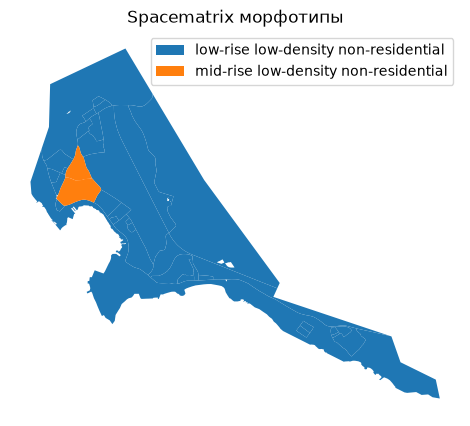

Сохранено: data\primorsk_blocksnet\blocks_spacematrix.geojson
Стрелка ok
Добавлены столбцы Стрелки: ['l', 'morphotype', 'mxi']
Распределение морфотипов:
morphotype
low-rise non-residential    34
NaN                          5
mid-rise non-residential     1
Name: count, dtype: int64


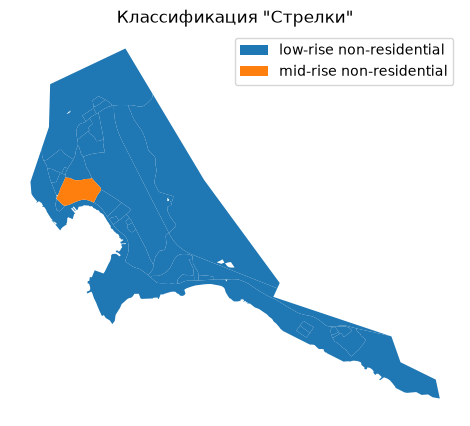

Сохранено: data\primorsk_blocksnet\blocks_strelka.geojson


In [70]:
# Spacematrix и Стрелка
from pathlib import Path
import matplotlib.pyplot as plt
import geopandas as gpd

from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes

DATA_DIR = Path('data/primorsk_blocksnet')
OUT_SM = DATA_DIR / 'blocks_spacematrix.geojson'
OUT_ST = DATA_DIR / 'blocks_strelka.geojson'

# Spacematrix
try:
    spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df, n_clusters=11, random_state=42)
    print('Spacematrix ok')
# Сохраняем геометрию кварталов и исходные показатели
    res_sm = blocks_d.copy()

# Добавляем только новые столбцы Spacematrix
    new_cols_sm = spacematrix_df.columns.difference(res_sm.columns)

    res_sm = res_sm.join(
        spacematrix_df[new_cols_sm]
    )

    print('Добавлены столбцы Spacematrix:', new_cols_sm.tolist())
    print('Столбцы результата:', res_sm.columns.tolist())
    fig, ax = plt.subplots(figsize=(7,5))
    res_sm.plot(column='morphotype', ax=ax, legend=True)
    ax.set_title('Spacematrix морфотипы')
    ax.set_axis_off()
    plt.show()
    res_sm.to_file(OUT_SM, driver='GeoJSON')
    print('Сохранено:', OUT_SM)
except Exception as e:
    print('ERR spacematrix:', e)
    raise

# Стрелка
try:
    strelka_df = get_strelka_morphotypes(density_df)
    print('Стрелка ok')
    # Сохраняем геометрию кварталов и исходные показатели
    res_st = blocks_d.copy()

# Добавляем только новые столбцы классификации «Стрелки»
    new_cols_st = strelka_df.columns.difference(res_st.columns)

    res_st = res_st.join(
        strelka_df[new_cols_st]
    )

    print('Добавлены столбцы Стрелки:', new_cols_st.tolist())
    print('Распределение морфотипов:')
    print(res_st['morphotype'].value_counts(dropna=False))
    fig, ax = plt.subplots(figsize=(7,5))
    res_st.plot(column='morphotype', ax=ax, legend=True)
    ax.set_title('Классификация "Стрелки"')
    ax.set_axis_off()
    plt.show()
    res_st.to_file(OUT_ST, driver='GeoJSON')
    print('Сохранено:', OUT_ST)
except Exception as e:
    print('ERR strelka:', e)
    raise


### 5.7. Анализ пространственной доступности (Area accessibility)

Используется blocksnet.analysis.network.accessibility.area.area_accessibility с матрицей пешеходного времени из accessibility_matrix_blocks_minutes.csv.


In [71]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd

DATA_DIR=Path("data/primorsk_blocksnet")
blocks=gpd.read_file(DATA_DIR/"blocks.geojson")
acc_df=pd.read_csv(DATA_DIR/"accessibility_matrix_blocks_minutes.csv",index_col=0)
acc_mx=acc_df.copy()
acc_mx.index=acc_mx.index.astype(int)
acc_mx.columns=acc_mx.columns.astype(int)
print("acc_mx",acc_mx.shape)


acc_mx (40, 40)


Площадь кварталов добавлена
   block_id     site_area
0         0  1.645911e+05
1         1  7.957411e+03
2         2  3.594429e+04
3         3  8.096970e+05
4         4  1.781217e+06
Кварталов для расчёта: 40
Столбцы: ['block_id', 'build_footprint_in_block', 'geometry', 'site_area']


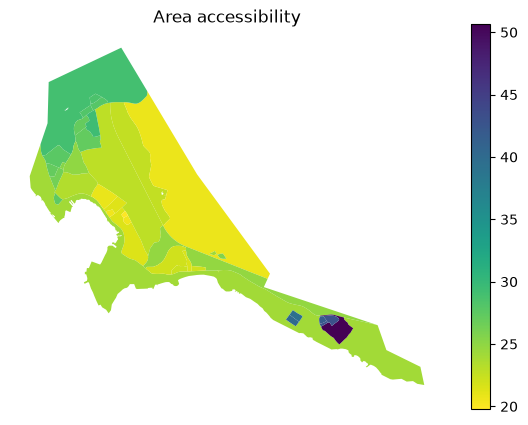

saved data\primorsk_blocksnet\blocks_area_accessibility.geojson


In [74]:
from pathlib import Path
import matplotlib.pyplot as plt
import geopandas as gpd
from blocksnet.analysis.network.accessibility.area import area_accessibility

DATA_DIR=Path("data/primorsk_blocksnet")
OUT_AA=DATA_DIR/"blocks_area_accessibility.geojson"
# Загружаем кварталы с уже рассчитанными характеристиками зданий
blocks_df = gpd.read_file(
    DATA_DIR / "blocks_with_buildings.geojson"
)

# Проверяем систему координат
blocks_df = blocks_df.to_crs(epsg=32635)

# Площадь каждого квартала в квадратных метрах
blocks_df['site_area'] = blocks_df.geometry.area

print('Площадь кварталов добавлена')
print(blocks_df[['block_id', 'site_area']].head())

# Проверяем количество кварталов
print("Кварталов для расчёта:", len(blocks_df))
print("Столбцы:", blocks_df.columns.tolist())
area_acc=area_accessibility(acc_mx,blocks_df,out=True)
res=blocks_df.copy().join(area_acc)
col=area_acc.columns[0]
fig,ax=plt.subplots(figsize=(7,5))
res.plot(column=col,ax=ax,legend=True,cmap="viridis_r")
ax.set_title("Area accessibility")
ax.set_axis_off()
plt.show()
res.to_file(OUT_AA,driver="GeoJSON")
print("saved",OUT_AA)


### 5.8. Сводные результаты и контроль полноты показателей

Сопоставление с оригинальным examples/pipeline.ipynb, сводка по всем рассчитанным показателям для 40 кварталов, диагностика и сохранение blocks_all_metrics.geojson.



In [75]:
# Проверка наличия выходных файлов
from pathlib import Path
DATA_DIR = Path('data/primorsk_blocksnet')
files = ['blocks.geojson','blocks_with_land_use.geojson','blocks_with_buildings.geojson','blocks_schools_provision.geojson','blocks_density.geojson','blocks_spacematrix.geojson','blocks_strelka.geojson','blocks_area_accessibility.geojson','accessibility_matrix_blocks_minutes.csv']
for f in files:
    print(f, (DATA_DIR/f).exists())


blocks.geojson True
blocks_with_land_use.geojson True
blocks_with_buildings.geojson True
blocks_schools_provision.geojson True
blocks_density.geojson True
blocks_spacematrix.geojson True
blocks_strelka.geojson True
blocks_area_accessibility.geojson True
accessibility_matrix_blocks_minutes.csv True


In [76]:
# Сбор сводной таблицы по 40 кварталам
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd

DATA_DIR = Path('data/primorsk_blocksnet')
OUT_ALL = DATA_DIR / 'blocks_all_metrics.geojson'

blocks = gpd.read_file(DATA_DIR / 'blocks.geojson').copy()
blocks['block_id'] = blocks.index
df_all = blocks[['block_id','geometry']].copy()

names = ['blocks_with_land_use.geojson','blocks_with_buildings.geojson','blocks_schools_provision.geojson','blocks_density.geojson','blocks_spacematrix.geojson','blocks_strelka.geojson','blocks_area_accessibility.geojson']
for name in names:
    try:
        g = gpd.read_file(DATA_DIR / name).copy()
        if 'block_id' not in g.columns:
            g['block_id'] = g.index
        drop_cols = ['geometry']
        for c in g.columns:
            if c != 'block_id' and c in df_all.columns:
                drop_cols.append(c)
        g2 = g.drop(columns=drop_cols, errors='ignore')
        df_all = df_all.merge(g2, on='block_id', how='left')
        print('merged', name)
    except Exception as e:
        print('skip', name, e)

print('shape', df_all.shape)
print('uniq', df_all['block_id'].nunique())
num = df_all.select_dtypes(include=[np.number])
print('neg', (num < 0).sum().sum())
df_all.to_file(OUT_ALL, driver='GeoJSON')
print('saved', OUT_ALL)


merged blocks_with_land_use.geojson
merged blocks_with_buildings.geojson
merged blocks_schools_provision.geojson
merged blocks_density.geojson
merged blocks_spacematrix.geojson
merged blocks_strelka.geojson
merged blocks_area_accessibility.geojson
shape (40, 53)
uniq 40
neg 0
saved data\primorsk_blocksnet\blocks_all_metrics.geojson


In [77]:
# Сопоставление с оригинальным examples/pipeline.ipynb
import pandas as pd
summary = pd.DataFrame([
    ['Land use assignment','5.2','blocks_with_land_use.geojson','DONE'],
    ['Buildings/imputation/population(model)','5.3','buildings_imputed.geojson, blocks_with_buildings.geojson','DONE'],
    ['Schools/provision_strong+weak','5.4','blocks_schools_provision.geojson','DONE'],
    ['Density/GSI/FSI','5.5','blocks_density.geojson','DONE'],
    ['Spacematrix','5.6','blocks_spacematrix.geojson','DONE'],
    ['Strelka','5.6','blocks_strelka.geojson','DONE'],
    ['Area accessibility','5.7','blocks_area_accessibility.geojson','DONE'],
    ['Synthesis','5.8','blocks_all_metrics.geojson','DONE'],
])
summary.columns = ['Показатель','Раздел','Файл','Статус']
display(summary)
print('Замечания: население ~9417 (модельное), вместимость школы ~250 (модельная), большая часть этажности восстановлена, скорость пешехода 5 км/ч, матрица только пешеходная.')


,Показатель,Раздел,Файл,Статус
0,Land use assignment,5.2,blocks_with_land_use.geojson,DONE
1,Buildings/imputation/population(model),5.3,"buildings_imputed.geojson, blocks_with_buildin...",DONE
2,Schools/provision_strong+weak,5.4,blocks_schools_provision.geojson,DONE
3,Density/GSI/FSI,5.5,blocks_density.geojson,DONE
4,Spacematrix,5.6,blocks_spacematrix.geojson,DONE
5,Strelka,5.6,blocks_strelka.geojson,DONE
6,Area accessibility,5.7,blocks_area_accessibility.geojson,DONE
7,Synthesis,5.8,blocks_all_metrics.geojson,DONE


Замечания: население ~9417 (модельное), вместимость школы ~250 (модельная), большая часть этажности восстановлена, скорость пешехода 5 км/ч, матрица только пешеходная.


## 6. Проверка результатов, план/методика/источники и инструкции повторного запуска

Раздел для итоговой сдачи.

### 6.1. Чек-лист проверки

- [ ] **Граница**: подтверждено, что используется именно город Приморск (проведена визуальная проверка)
- [ ] **Визуализация**: проверены граница, береговая линия/водоёмы, дороги, ж/д, полученные кварталы
- [ ] **Кварталы**: созданы/загружены, сохранены в `data/primorsk_blocksnet/blocks.geojson`
- [ ] **Граф**: загружен только пешеходный (`walk`), без интермодала. Источник указан (OSM/osmnx). Сохранён в `data/primorsk_blocksnet/graph.graphml`. Время переведено в **минуты**
- [ ] **Показатели**: посчитаны **все** показатели из `examples/pipeline.ipynb`, включая **оба** показателя обеспеченности школами и **обе** классификации типов застройки
- [ ] **Сохранение**: все слои/результаты сохранены в `GeoJSON`, предусмотрено переиспользование файлов
- [ ] **Остановка**: после подготовки кварталов была соблюдена (спросил про доступные метрики перед расчётом)

### 6.2. План, основные запросы, методика, источники данных (для сдачи)

**План исследования (кратко):**
1. Подготовка окружения и проверка версий (blocksnet 1.0.0a9)
2. Получение границы города Приморск (проверка: именно город, не поселение) + визуальная проверка
3. Загрузка слоёв OSM (дороги, ж/д, вода) по тегам, фильтрация, приведение CRS, визуальная проверка
4. Предобработка и нарезка кварталов через `preprocess_urban_objects`/`cut_urban_blocks`, визуальная проверка, сохранение
5. **Остановка** после кварталов, согласование доступных метрик
6. Загрузка пешеходного графа OSM (`walk`, единственный, без интермодала), сохранение `graph.graphml`, расчёт времени между кварталами в минутах
7. Расчёт всех показателей из pipeline.ipynb (включая оба показателя школ и обе классификации застройки)
8. Сохранение всех результатов в GeoJSON, проверка и подготовка к отдельному этапу - созданию HTML-страницы с картой и дашбордом

**Основные запросы к данным:**
- Граница: `Приморск, Выборгский район, Ленинградская область, Россия` (проверка соответствия "город Приморск")
- Слои: roads/railways/water по тегам из `blocksnet/examples/pipeline.ipynb`
- Граф: `ox.graph_from_place` с `network_type='walk'`

**Методика:**
- Нарезка кварталов по линейным и полигональным препятствиям (дороги, ж/д, вода) с использованием методов BlocksNet
- Пешеходная доступность по улично-дорожной сети OSM (только walk), время в пути рассчитывается по графу, переводится в минуты
- Все индикаторы рассчитываются по подходу из оригинального `pipeline.ipynb` BlocksNet

**Источники данных:**
- OpenStreetMap через `osmnx` (границы, объекты инфраструктуры, пешеходная сеть)
- BlocksNet 1.0.0.a9, примеры: https://github.com/aimclub/blocksnet (особенно `examples/pipeline.ipynb`)
- Текущий учебный проект в репозитории

**Зависимости:**
- Основные: `blocksnet==1.0.0a9`, `geopandas`, `osmnx`, `networkx`, `shapely`, `pyproj`
- В `pyproject.toml` текущего проекта `blocksnet` отсутствует (отмечено для добавления в дальнейшем, второй файл зависимостей не создавался)

### 6.3. Инструкции повторного запуска (Windows, PowerShell)

**Подготовка окружения:**
```powershell
cd "D:\ИТМО\Курс ИИ технологии\python-package-boilerplate"
.\.venv\Scripts\Activate.ps1
jupyter lab
# или jupyter notebook
```

**Порядок запуска ячеек:**
1. Раздел 1 - проверка версий (только проверка)
2. Раздел 2 - создание `data/primorsk_blocksnet/`
3. Раздел 3.1-3.4 - граница (проверка именно города Приморск + визуализация), слои, нарезка кварталов. **Сохранить `blocks.geojson`**
4. **ОСТАНОВКА** - спросить про доступные метрики. Не идти дальше, пока не получен ответ
5. Раздел 4 - пешеходный граф `walk` (проверка `graph.graphml`, иначе загрузка и сохранение). Расчёт времени в **минутах** по единственному графу
6. Раздел 5 - **все** показатели из pipeline.ipynb (оба показателя школ, обе классификации застройки). Сохранять результаты в GeoJSON
7. Раздел 6 - проверка по чек-листу

**Повторное использование без скачивания:**
- Если есть `data/primorsk_blocksnet/boundary_primorsk.geojson`, `water.geojson`, `roads.geojson`, `railways.geojson` - ячейки загрузят их из файлов
- Если есть `blocks.geojson` - можно загрузить вместо повторной нарезки
- Если есть `graph.graphml` - граф загрузится из файла, **нового скачивания не будет**
- Если есть сохранённые результаты показателей - можно загрузить их вместо пересчёта

**Базовые советы при проблемах:**
- Если граница получилась не той (включает поселение) - проверить визуализацию в 3.1, при необходимости использовать более точный запрос
- Если не находит модули - проверить активацию venv и версии из раздела 1
- Если проблемы с CRS при поиске узлов графа - сверить CRS графа и кварталов
- Помнить: **только один граф (walk), без интермодала**, время в **минутах**

**Файл создан:** `primorsk_blocksnet_pipeline.ipynb`  
**Папка для данных:** `data/primorsk_blocksnet/` (будет создана при запуске ячейки раздела 2)  
**Статус:** только создание. Ничего не скачано, не запущено, `pyproject.toml` не изменён.  
**Следующий шаг:** ты запускаешь ячейки ноутбука самостоятельно по порядку с соблюдением остановки после раздела 3.